# Italy - National Market Analysis

<!-- STRUCTURE
1. [Initial setup](#1-initial-setup)  
    1.1. [Dataset loading and timespan definition ](#11-dataset-loading-and-timespan-definition)  
    1.2. [Variables building](#12-variables-building)  
2. [Data Analysis](#2-data-analysis)  
    2.1. [Descriptive statistics](#21-descriptive-statistics)  
    2.2. [Distribution analysis](#22-distribution-analysis)  
    2.3. [Time series analysis](#23-time-series-analysis)  
    2.4. [Relationship analysis](#24-relationship-analysis)  
    2.5. [Renewable penetration and market regimes](#25-renewable-penetration-and-market-regimes)  
-->

# 1. Initial setup 

## 1.1. Imports and configuration

In [ ]:
# import libraries
import pandas as pd
import numpy as np
import warnings
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go 
import seaborn as sns
from pathlib import Path
from scipy.stats import pearsonr

# filter User and Filter Warnings for privacy matters
warnings.simplefilter(action='ignore', category=UserWarning)
warnings.simplefilter(action='ignore', category=FutureWarning)

In [ ]:
# user input data --> user parameters configuration
zone = 'IT'
price_col_name = 'PUN'
load_col_name = 'National Load'
timezone = 'Europe/Rome'
start = '2016-01-01 00:00'
end = '2026-06-28 23:00'

## 1.2. Dataset loading and timespan definition

In [4]:
# define dataset folder path
dataset_path = Path('../dataset/filled')

# read dataset
df = pd.read_csv(dataset_path / f'{zone}.csv')

# fix datetime timezones 
df['datetime_UTC'] = pd.to_datetime(df['datetime_UTC'], utc=True)
df['datetime_local'] = pd.to_datetime(df['datetime_local'], utc=True)
df['datetime_local'] = df['datetime_local'].dt.tz_convert(f'{timezone}')

In [5]:
df

,datetime_UTC,datetime_local,local_hour,PUN,National Load,Biomass,Fossil Coal-derived gas,Fossil Gas,Fossil Hard coal,Fossil Oil,...,Hydro Run-of-river and poundage,Hydro Water Reservoir,Other,Solar,Waste,Wind Onshore,Wind Offshore,Energy storage,Other renewable,Geothermal_source
0,2015-12-31 23:00:00+00:00,2016-01-01 00:00:00+01:00,0,50.41211,23927.233,220.00,241.00,5588.00,1686.00,542.00,...,1259.00,287.00,9112.00,0.00,45.0,203.00,0.00,NaN,NaN,ENTSO-E
1,2016-01-01 00:00:00+00:00,2016-01-01 01:00:00+01:00,1,44.76435,22517.279,216.00,241.00,5034.00,1719.00,519.00,...,1163.00,81.00,9324.00,1.00,46.0,218.00,0.00,NaN,NaN,ENTSO-E
2,2016-01-01 01:00:00+00:00,2016-01-01 02:00:00+01:00,2,40.01613,21354.678,217.00,241.00,4486.00,1728.00,530.00,...,1089.00,20.00,8739.00,0.00,44.0,267.00,0.00,NaN,NaN,ENTSO-E
3,2016-01-01 02:00:00+00:00,2016-01-01 03:00:00+01:00,3,37.92076,20219.874,216.00,241.00,4275.00,1727.00,467.00,...,1010.00,20.00,8195.00,0.00,39.0,227.00,0.00,NaN,NaN,ENTSO-E
4,2016-01-01 03:00:00+00:00,2016-01-01 04:00:00+01:00,4,35.77287,19229.221,215.00,241.00,3926.00,1658.00,426.00,...,988.00,20.00,7876.00,0.00,44.0,212.00,0.00,NaN,NaN,ENTSO-E
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92010,2026-06-30 17:00:00+00:00,2026-06-30 19:00:00+02:00,19,204.10622,48437.300,712.50,641.50,26968.25,394.75,155.75,...,4189.75,1167.25,1709.00,1755.75,NaN,1780.75,1.00,1148.333333,NaN,ENTSO-E
92011,2026-06-30 18:00:00+00:00,2026-06-30 20:00:00+02:00,20,198.16000,47383.500,714.00,661.75,27442.75,396.50,156.00,...,4343.25,1209.75,1767.00,252.00,NaN,2076.50,5.75,1273.750000,NaN,ENTSO-E
92012,2026-06-30 19:00:00+00:00,2026-06-30 21:00:00+02:00,21,182.03250,45951.100,716.50,676.50,27084.00,392.25,156.00,...,4252.50,982.50,1793.50,0.50,NaN,2587.75,5.50,830.333333,NaN,ENTSO-E
92013,2026-06-30 20:00:00+00:00,2026-06-30 22:00:00+02:00,22,173.30306,43204.200,710.25,647.50,26959.75,365.75,158.25,...,3931.75,618.00,1792.25,0.00,NaN,2068.75,1.25,241.750000,NaN,ENTSO-E


In [6]:
# filter dataset by period of time
start_date = pd.Timestamp(
    f'{start}',
    tz='Europe/Rome'
)

end_date = pd.Timestamp(
    f'{end}',
    tz='Europe/Rome'
)

df = df[
    df['datetime_local'].between(start_date, end_date)
].copy()

In [7]:
df

,datetime_UTC,datetime_local,local_hour,PUN,National Load,Biomass,Fossil Coal-derived gas,Fossil Gas,Fossil Hard coal,Fossil Oil,...,Hydro Run-of-river and poundage,Hydro Water Reservoir,Other,Solar,Waste,Wind Onshore,Wind Offshore,Energy storage,Other renewable,Geothermal_source
0,2015-12-31 23:00:00+00:00,2016-01-01 00:00:00+01:00,0,50.41211,23927.233,220.00,241.00,5588.00,1686.00,542.00,...,1259.00,287.00,9112.00,0.00,45.0,203.00,0.00,NaN,NaN,ENTSO-E
1,2016-01-01 00:00:00+00:00,2016-01-01 01:00:00+01:00,1,44.76435,22517.279,216.00,241.00,5034.00,1719.00,519.00,...,1163.00,81.00,9324.00,1.00,46.0,218.00,0.00,NaN,NaN,ENTSO-E
2,2016-01-01 01:00:00+00:00,2016-01-01 02:00:00+01:00,2,40.01613,21354.678,217.00,241.00,4486.00,1728.00,530.00,...,1089.00,20.00,8739.00,0.00,44.0,267.00,0.00,NaN,NaN,ENTSO-E
3,2016-01-01 02:00:00+00:00,2016-01-01 03:00:00+01:00,3,37.92076,20219.874,216.00,241.00,4275.00,1727.00,467.00,...,1010.00,20.00,8195.00,0.00,39.0,227.00,0.00,NaN,NaN,ENTSO-E
4,2016-01-01 03:00:00+00:00,2016-01-01 04:00:00+01:00,4,35.77287,19229.221,215.00,241.00,3926.00,1658.00,426.00,...,988.00,20.00,7876.00,0.00,44.0,212.00,0.00,NaN,NaN,ENTSO-E
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91962,2026-06-28 17:00:00+00:00,2026-06-28 19:00:00+02:00,19,159.01250,39430.200,669.50,484.00,18400.75,0.00,167.00,...,3676.25,722.50,1688.25,1775.25,NaN,950.75,0.00,829.00,NaN,ENTSO-E
91963,2026-06-28 18:00:00+00:00,2026-06-28 20:00:00+02:00,20,156.20537,39870.800,669.00,484.00,19244.75,39.25,166.75,...,3990.50,870.00,1693.75,194.00,NaN,708.75,0.00,1178.75,NaN,ENTSO-E
91964,2026-06-28 19:00:00+00:00,2026-06-28 21:00:00+02:00,21,158.80250,39625.500,681.00,483.25,20084.50,129.00,167.00,...,3914.50,661.50,1708.75,0.00,NaN,565.75,0.50,1312.50,NaN,ENTSO-E
91965,2026-06-28 20:00:00+00:00,2026-06-28 22:00:00+02:00,22,155.93208,38308.300,684.75,481.25,19984.00,223.25,167.00,...,3726.75,559.75,1703.00,0.00,NaN,486.75,0.50,874.00,NaN,ENTSO-E


## 1.3. Variables building

In [8]:
df.columns.tolist()

['datetime_UTC',
 'datetime_local',
 'local_hour',
 'PUN',
 'National Load',
 'Biomass',
 'Fossil Coal-derived gas',
 'Fossil Gas',
 'Fossil Hard coal',
 'Fossil Oil',
 'Geothermal',
 'Hydro Pumped Storage',
 'Hydro Run-of-river and poundage',
 'Hydro Water Reservoir',
 'Other',
 'Solar',
 'Waste',
 'Wind Onshore',
 'Wind Offshore',
 'Energy storage',
 'Other renewable',
 'Geothermal_source']

In [9]:
# report amount of missing values
missing = df.isna().sum()
missing = missing[missing > 0]

print('\n--- MISSING VALUES ---')
print(missing)


--- MISSING VALUES ---
Fossil Coal-derived gas      598
Fossil Gas                   145
Fossil Hard coal             500
Fossil Oil                   746
Geothermal                    48
Hydro Pumped Storage        7265
Hydro Water Reservoir         24
Other                        288
Waste                       2303
Wind Onshore                   8
Wind Offshore                864
Energy storage             82794
Other renewable            87458
dtype: int64


Main variables:
- Total_Generation_approx: broader approximate generation aggregate
- Total_Generation_core: generation from selected core technologies
- RES_core: selected renewable generation
- RES_share_core: share of RES within the selected core generation mix
- Residual_Demand_core: national load minus RES_core

In [10]:
# map technology groups
wind = ['Wind Onshore', 'Wind Offshore']
hydro = ['Hydro Run-of-river and poundage', 'Hydro Water Reservoir']

res_core = [
    'Biomass',
    'Geothermal',
    'Hydro Run-of-river and poundage',
    'Hydro Water Reservoir',
    'Wind Onshore', 
    'Wind Offshore',
    'Solar'
]

fossil = [
    'Fossil Coal-derived gas', 
    'Fossil Gas', 
    'Fossil Hard coal', 
    'Fossil Oil'
]

Broader approximate generation aggregate.  
Energy Storage, Hydro Pumped Storage and Other renewable are excluded.  
Other and Waste are retained, although their classification and/or data coverage require caution.

In [11]:
generation_approx_cols = [
    'Biomass',
    'Fossil Coal-derived gas',
    'Fossil Gas',
    'Fossil Hard coal',
    'Fossil Oil',
    'Geothermal',
    'Hydro Run-of-river and poundage',
    'Hydro Water Reservoir',
    'Other',
    'Solar',
    'Waste',
    'Wind Onshore',
    'Wind Offshore'
]

# core aggregate: only selected RES and fossil technologies
total_gen_core_cols = list(dict.fromkeys(res_core + fossil))

# check that all expected source columns exist
required_cols = list(dict.fromkeys(
    generation_approx_cols + total_gen_core_cols
))

missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    raise KeyError(f'Missing generation columns: {missing_cols}')

In [12]:
# aggregate generation by technology
df['Hydro'] = df[hydro].sum(axis=1, min_count=len(hydro))
df['Wind'] = df[wind].sum(axis=1, min_count=len(wind))
df['Fossil'] = df[fossil].sum(axis=1, min_count=len(fossil))
df['RES_core'] = df[res_core].sum(
    axis=1,
    min_count=len(res_core)
)

In [13]:
# approximate broader generation total - value is computed only when all included components are observed
df['Total_Generation_approx'] = df[generation_approx_cols].sum(
    axis=1,
    min_count=len(generation_approx_cols)
)

df['Generation_approx_missing_components'] = (
    df[generation_approx_cols].isna().sum(axis=1)
)

df['Generation_approx_completeness_pct'] = (
    df[generation_approx_cols].notna().mean(axis=1) * 100
)

In [14]:
# core generation total
df['Total_Generation_core'] = df[total_gen_core_cols].sum(
    axis=1,
    min_count=len(total_gen_core_cols)
)

df['Core_Generation_Missing_Components'] = (
    df[total_gen_core_cols].isna().sum(axis=1)
)

df['Core_Generation_Completeness_pct'] = (
    df[total_gen_core_cols].notna().mean(axis=1) * 100
)

In [15]:
# core renewable share and residual demand
df['RES_share_core'] = (
    df['RES_core'] / df['Total_Generation_core']
)

df['Residual_Demand_core'] = (
    df['National Load'] - df['RES_core']
)

In [16]:
df

,datetime_UTC,datetime_local,local_hour,PUN,National Load,Biomass,Fossil Coal-derived gas,Fossil Gas,Fossil Hard coal,Fossil Oil,...,Fossil,RES_core,Total_Generation_approx,Generation_approx_missing_components,Generation_approx_completeness_pct,Total_Generation_core,Core_Generation_Missing_Components,Core_Generation_Completeness_pct,RES_share_core,Residual_Demand_core
0,2015-12-31 23:00:00+00:00,2016-01-01 00:00:00+01:00,0,50.41211,23927.233,220.00,241.00,5588.00,1686.00,542.00,...,8057.00,2675.00,19889.0,0,100.000000,10732.00,0,100.0,0.249255,21252.233
1,2016-01-01 00:00:00+00:00,2016-01-01 01:00:00+01:00,1,44.76435,22517.279,216.00,241.00,5034.00,1719.00,519.00,...,7513.00,2385.00,19268.0,0,100.000000,9898.00,0,100.0,0.240958,20132.279
2,2016-01-01 01:00:00+00:00,2016-01-01 02:00:00+01:00,2,40.01613,21354.678,217.00,241.00,4486.00,1728.00,530.00,...,6985.00,2299.00,18067.0,0,100.000000,9284.00,0,100.0,0.247630,19055.678
3,2016-01-01 02:00:00+00:00,2016-01-01 03:00:00+01:00,3,37.92076,20219.874,216.00,241.00,4275.00,1727.00,467.00,...,6710.00,2178.00,17122.0,0,100.000000,8888.00,0,100.0,0.245050,18041.874
4,2016-01-01 03:00:00+00:00,2016-01-01 04:00:00+01:00,4,35.77287,19229.221,215.00,241.00,3926.00,1658.00,426.00,...,6251.00,2142.00,16313.0,0,100.000000,8393.00,0,100.0,0.255213,17087.221
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91962,2026-06-28 17:00:00+00:00,2026-06-28 19:00:00+02:00,19,159.01250,39430.200,669.50,484.00,18400.75,0.00,167.00,...,19051.75,8340.25,NaN,1,92.307692,27392.00,0,100.0,0.304478,31089.950
91963,2026-06-28 18:00:00+00:00,2026-06-28 20:00:00+02:00,20,156.20537,39870.800,669.00,484.00,19244.75,39.25,166.75,...,19934.75,6978.50,NaN,1,92.307692,26913.25,0,100.0,0.259296,32892.300
91964,2026-06-28 19:00:00+00:00,2026-06-28 21:00:00+02:00,21,158.80250,39625.500,681.00,483.25,20084.50,129.00,167.00,...,20863.75,6374.50,NaN,1,92.307692,27238.25,0,100.0,0.234028,33251.000
91965,2026-06-28 20:00:00+00:00,2026-06-28 22:00:00+02:00,22,155.93208,38308.300,684.75,481.25,19984.00,223.25,167.00,...,20855.50,6010.50,NaN,1,92.307692,26866.00,0,100.0,0.223721,32297.800


## 1.4. Market regimes and calendar variables

**Market regimes** are predefined analytical periods, while **calendar variables** control for recurring hourly, weekly and seasonal patterns.

| Name          | From       | To         | Description |
|---------------|------------|------------|-------------|
| Pre_crises    | 2016       | 2020-03-08 | Market before the energy crisis |
| Demand_crisis | 2020-03-09 | 2021-06-30 | COVID pandemic demand crisis |
| Supply crisis | 2021-07-01 | 2023-04-30 | European gas-market tightening, intensified by Russia's invasion of Ukraine |
| Post_crises   | 2023-05-01 | 2026       | Current market |

In [17]:
# reconstruct local time from the canonical UTC timestamp
df['datetime_UTC'] = pd.to_datetime(
    df['datetime_UTC'],
    utc=True
)

df['datetime_local'] = (
    df['datetime_UTC'].dt.tz_convert(timezone)
)

# calendar variables
df['local_hour'] = df['datetime_local'].dt.hour
df['day_of_week'] = df['datetime_local'].dt.dayofweek
df['local_month'] = df['datetime_local'].dt.month

# market regime cutoffs
cut_demand = pd.Timestamp(
    '2020-03-09 00:00', tz=timezone
)
cut_supply = pd.Timestamp(
    '2021-07-01 00:00', tz=timezone
)
cut_post = pd.Timestamp(
    '2023-05-01 00:00', tz=timezone
)

conditions = [
    df['datetime_local'] < cut_demand,
    df['datetime_local'] < cut_supply,
    df['datetime_local'] < cut_post
]

choices = [
    'Pre_crises',
    'Demand_crisis',
    'Supply_crisis'
]

df['Period'] = np.select(
    conditions,
    choices,
    default='Post_crises'
)

# define the category order for readability
period_categories = [
    'Pre_crises',
    'Demand_crisis',
    'Supply_crisis',
    'Post_crises'
]

df['Period'] = pd.Categorical(
    df['Period'],
    categories=period_categories,
    ordered=True
)

# check period coverage
period_summary = (
    df.groupby('Period', observed=True)
    .agg(
        first_date=('datetime_local', 'min'),
        last_date=('datetime_local', 'max'),
        observations=('datetime_local', 'size')
    )
)

period_summary

,first_date,last_date,observations
Period,,,
Pre_crises,2016-01-01 00:00:00+01:00,2020-03-08 23:00:00+01:00,36696
Demand_crisis,2020-03-09 00:00:00+01:00,2021-06-30 23:00:00+02:00,11495
Supply_crisis,2021-07-01 00:00:00+02:00,2023-04-30 23:00:00+02:00,16056
Post_crises,2023-05-01 00:00:00+02:00,2026-06-28 23:00:00+02:00,27720


In [18]:
df

,datetime_UTC,datetime_local,local_hour,PUN,National Load,Biomass,Fossil Coal-derived gas,Fossil Gas,Fossil Hard coal,Fossil Oil,...,Generation_approx_missing_components,Generation_approx_completeness_pct,Total_Generation_core,Core_Generation_Missing_Components,Core_Generation_Completeness_pct,RES_share_core,Residual_Demand_core,day_of_week,local_month,Period
0,2015-12-31 23:00:00+00:00,2016-01-01 00:00:00+01:00,0,50.41211,23927.233,220.00,241.00,5588.00,1686.00,542.00,...,0,100.000000,10732.00,0,100.0,0.249255,21252.233,4,1,Pre_crises
1,2016-01-01 00:00:00+00:00,2016-01-01 01:00:00+01:00,1,44.76435,22517.279,216.00,241.00,5034.00,1719.00,519.00,...,0,100.000000,9898.00,0,100.0,0.240958,20132.279,4,1,Pre_crises
2,2016-01-01 01:00:00+00:00,2016-01-01 02:00:00+01:00,2,40.01613,21354.678,217.00,241.00,4486.00,1728.00,530.00,...,0,100.000000,9284.00,0,100.0,0.247630,19055.678,4,1,Pre_crises
3,2016-01-01 02:00:00+00:00,2016-01-01 03:00:00+01:00,3,37.92076,20219.874,216.00,241.00,4275.00,1727.00,467.00,...,0,100.000000,8888.00,0,100.0,0.245050,18041.874,4,1,Pre_crises
4,2016-01-01 03:00:00+00:00,2016-01-01 04:00:00+01:00,4,35.77287,19229.221,215.00,241.00,3926.00,1658.00,426.00,...,0,100.000000,8393.00,0,100.0,0.255213,17087.221,4,1,Pre_crises
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91962,2026-06-28 17:00:00+00:00,2026-06-28 19:00:00+02:00,19,159.01250,39430.200,669.50,484.00,18400.75,0.00,167.00,...,1,92.307692,27392.00,0,100.0,0.304478,31089.950,6,6,Post_crises
91963,2026-06-28 18:00:00+00:00,2026-06-28 20:00:00+02:00,20,156.20537,39870.800,669.00,484.00,19244.75,39.25,166.75,...,1,92.307692,26913.25,0,100.0,0.259296,32892.300,6,6,Post_crises
91964,2026-06-28 19:00:00+00:00,2026-06-28 21:00:00+02:00,21,158.80250,39625.500,681.00,483.25,20084.50,129.00,167.00,...,1,92.307692,27238.25,0,100.0,0.234028,33251.000,6,6,Post_crises
91965,2026-06-28 20:00:00+00:00,2026-06-28 22:00:00+02:00,22,155.93208,38308.300,684.75,481.25,19984.00,223.25,167.00,...,1,92.307692,26866.00,0,100.0,0.223721,32297.800,6,6,Post_crises


## 1.5. Multiple imputation for generation visualization

In [19]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge

# preserve the original dataset
df_viz = df.copy()

# preserve the original observed generation aggregate
df_viz["Total_Generation_approx_observed"] = (
    df["Total_Generation_approx"]
)

# generation variables to be imputed
generation_cols = generation_approx_cols.copy()

# check for columns with no observed values at all
all_missing = [
    col for col in generation_cols
    if df_viz[col].isna().all()
]

if all_missing:
    raise ValueError(
        f'Cannot impute entirely missing columns: {all_missing}'
    )

# cyclical calendar features
hour = df_viz['datetime_local'].dt.hour
dow = df_viz['datetime_local'].dt.dayofweek
month = df_viz['datetime_local'].dt.month

df_viz['hour_sin'] = np.sin(2 * np.pi * hour / 24)
df_viz['hour_cos'] = np.cos(2 * np.pi * hour / 24)

df_viz['dow_sin'] = np.sin(2 * np.pi * dow / 7)
df_viz['dow_cos'] = np.cos(2 * np.pi * dow / 7)

df_viz['month_sin'] = np.sin(2 * np.pi * (month - 1) / 12)
df_viz['month_cos'] = np.cos(2 * np.pi * (month - 1) / 12)

calendar_cols = [
    'hour_sin', 'hour_cos',
    'dow_sin', 'dow_cos',
    'month_sin', 'month_cos'
]

# use generation, national load and seasonality as predictors
feature_cols = (
    generation_cols
    + [load_col_name]
    + calendar_cols
)

# lower and upper bounds for the features: generation and load cannot be negative;
# cyclical features lie between -1 and 1.
lower_bounds = (
    [0.0] * len(generation_cols)
    + [0.0]
    + [-1.0] * len(calendar_cols)
)

upper_bounds = (
    [np.inf] * (len(generation_cols) + 1)
    + [1.0] * len(calendar_cols)
)

X = df_viz[feature_cols].astype(float)

# generate five alternative imputations
imputed_draws = []

for seed in range(5):
    imputer = IterativeImputer(
        estimator=BayesianRidge(),
        max_iter=10,
        sample_posterior=True,
        min_value=lower_bounds,
        max_value=upper_bounds,
        random_state=seed
    )

    X_imputed = imputer.fit_transform(X)

    imputed_draws.append(
        pd.DataFrame(
            X_imputed,
            columns=feature_cols,
            index=df_viz.index
        )[generation_cols]
    )

# median across imputations for visualization summary only
imputed_stack = np.stack(
    [draw.to_numpy() for draw in imputed_draws],
    axis=0
)

imputed_median = np.median(imputed_stack, axis=0)

# replace values only in the visualization copy,preserving all observed generation values
for j, col in enumerate(generation_cols):
    missing_mask = df_viz[col].isna()

    df_viz.loc[missing_mask, col] = (
        imputed_median[missing_mask.to_numpy(), j]
    )

# recalculate the broader generation aggregate
df_viz['Total_Generation_approx'] = df_viz[
    generation_cols
].sum(axis=1, min_count=len(generation_cols))

# separate observed and imputed values for plotting
df_viz["Total_Generation_observed_plot"] = (
    df_viz["Total_Generation_approx_observed"]
)
df_viz["Total_Generation_imputed_plot"] = (
    df_viz["Total_Generation_approx"].where(
        df_viz["Total_Generation_approx_observed"].isna()
    )
)

# report imputation results
print('Original missing values:')
print(df[generation_cols].isna().sum())

print('\nMissing values after imputation (visualization copy):')
print(df_viz[generation_cols].isna().sum())

print('\nOriginal dataset unchanged:', df[generation_cols].isna().sum().sum()
      == df[generation_cols].isna().sum().sum())


Original missing values:
Biomass                               0
Fossil Coal-derived gas             598
Fossil Gas                          145
Fossil Hard coal                    500
Fossil Oil                          746
Geothermal                           48
Hydro Run-of-river and poundage       0
Hydro Water Reservoir                24
Other                               288
Solar                                 0
Waste                              2303
Wind Onshore                          8
Wind Offshore                       864
dtype: int64

Missing values after imputation (visualization copy):
Biomass                            0
Fossil Coal-derived gas            0
Fossil Gas                         0
Fossil Hard coal                   0
Fossil Oil                         0
Geothermal                         0
Hydro Run-of-river and poundage    0
Hydro Water Reservoir              0
Other                              0
Solar                              0
Waste            

In [20]:
# verify that all originally observed generation values are unchanged
for col in generation_cols:
    observed = df[col].notna()

    assert np.allclose(
        df.loc[observed, col].to_numpy(),
        df_viz.loc[observed, col].to_numpy(),
        equal_nan=True
    )

print("All originally observed generation values are unchanged.")

All originally observed generation values are unchanged.


# 2. Exploratory Data Analysis

## 2.1. Descriptive statistics
Descriptive statistics includes measures of central tendency, dispersion and distribution shape through the ten-years time span.

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 91967 entries, 0 to 91966
Data columns (total 37 columns):
 #   Column                                Non-Null Count  Dtype                      
---  ------                                --------------  -----                      
 0   datetime_UTC                          91967 non-null  datetime64[us, UTC]        
 1   datetime_local                        91967 non-null  datetime64[us, Europe/Rome]
 2   local_hour                            91967 non-null  int32                      
 3   PUN                                   91967 non-null  float64                    
 4   National Load                         91967 non-null  float64                    
 5   Biomass                               91967 non-null  float64                    
 6   Fossil Coal-derived gas               91369 non-null  float64                    
 7   Fossil Gas                            91822 non-null  float64                    
 8   Fossil Hard coal           

In [22]:
cols_long = [
    'PUN',
    'National Load',
    'Biomass',
    'Fossil Coal-derived gas',
    'Fossil Gas',
    'Fossil Hard coal',
    'Geothermal',
    'Other',
    'Solar',
    'Waste',
    'Hydro',
    'Wind',
    'Fossil',
    'RES_share_core',
    'Total_Generation_approx',
    'Residual_Demand_core'
]

In [23]:
summary = []

for col in cols_long:
    q1 = df[col].quantile(0.25)
    q2 = df[col].quantile(0.50)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    std = df[col].std()
    mean = df[col].mean()

    summary.append({
        'variable': col,
        'count': df[col].count(),
        'mean': mean,
        'std': std,
        'median': df[col].median(),
        'min': df[col].min(),
        '25%': q1,
        '50%': q2,
        '75%': q3,
        'max': df[col].max()
        #'std': std,
        #'variance': df[col].var(),
        #'range': df[col].max() - df[col].min(),
        #'IQR': iqr,
        #'RSD': std / mean
    })

summary_df = pd.DataFrame(summary)
summary_df

,variable,count,mean,std,median,min,25%,50%,75%,max
0,PUN,91967,104.121598,90.184017,75.000000,0.000000,48.18080,75.000000,125.269695,870.000000
1,National Load,91967,32158.243225,6705.490372,31728.600000,16272.977000,26280.04050,31728.600000,37838.495000,50312.747000
2,Biomass,91967,532.784409,165.109453,587.000000,151.000000,384.00000,587.000000,669.000000,849.500000
3,Fossil Coal-derived gas,91369,471.513016,228.530898,484.750000,0.000000,250.00000,484.750000,644.000000,1135.000000
4,Fossil Gas,91822,10917.530584,5140.503643,10166.750000,1051.500000,6864.00000,10166.750000,14286.812500,31198.000000
5,Fossil Hard coal,91467,1522.102040,1066.602889,1342.000000,0.000000,537.00000,1342.000000,2236.000000,6198.000000
6,Geothermal,91919,631.209368,31.112859,632.000000,460.500000,606.00000,632.000000,657.000000,707.000000
7,Other,91679,3988.571576,3470.739427,2261.000000,193.000000,1752.00000,2261.000000,5729.500000,19489.000000
8,Solar,91967,2626.083246,3787.724004,76.250000,0.000000,0.00000,76.250000,4830.500000,26085.000000
9,Waste,89664,82.076681,111.062854,39.000000,0.000000,30.00000,39.000000,47.000000,409.000000


## 2.2. Distribution analysis

In [24]:
dist_summary = []

cols = [f'{price_col_name}', f'{load_col_name}', 'Total_Generation_approx']

for col in cols:
    skewness = df[col].skew()
    kurtosis = df[col].kurt()

    dist_summary.append({
        'variable': col,
        'skewness': skewness,
        'kurtosis': kurtosis,
    })

dist_summary_df = pd.DataFrame(dist_summary)
dist_summary_df

,variable,skewness,kurtosis
0,PUN,2.787051,10.621977
1,National Load,0.125888,-1.073565
2,Total_Generation_approx,0.187975,-0.851047


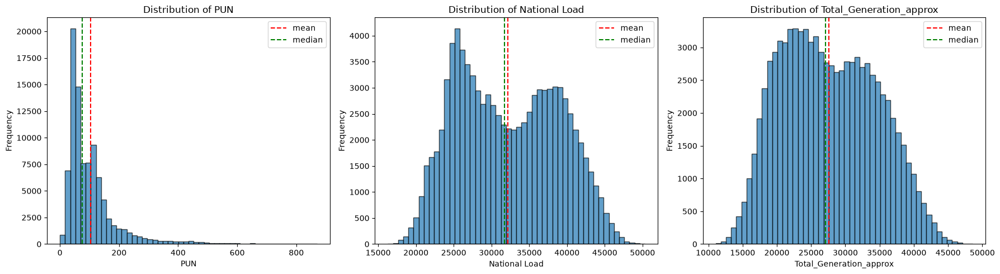

In [25]:
#create plot
fig, axes = plt.subplots(1, len(cols), figsize=(18, 5))

for i, col in enumerate(cols):
    axes[i].hist(df[col], bins=50, edgecolor='black', alpha=0.7)
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')
    axes[i].axvline(df[col].mean(), color='red', linestyle='--', label='mean')
    axes[i].axvline(df[col].median(), color='green', linestyle='--', label='median')
    axes[i].legend()

plt.tight_layout()
plt.show()

## 2.3. Time series analysis

In this section, since the project aim to analyze the relationship between Prices, Load and Generation, time series evolution of those variables are displayed during the ten-years time span.

### 2.3.1. Raw time series

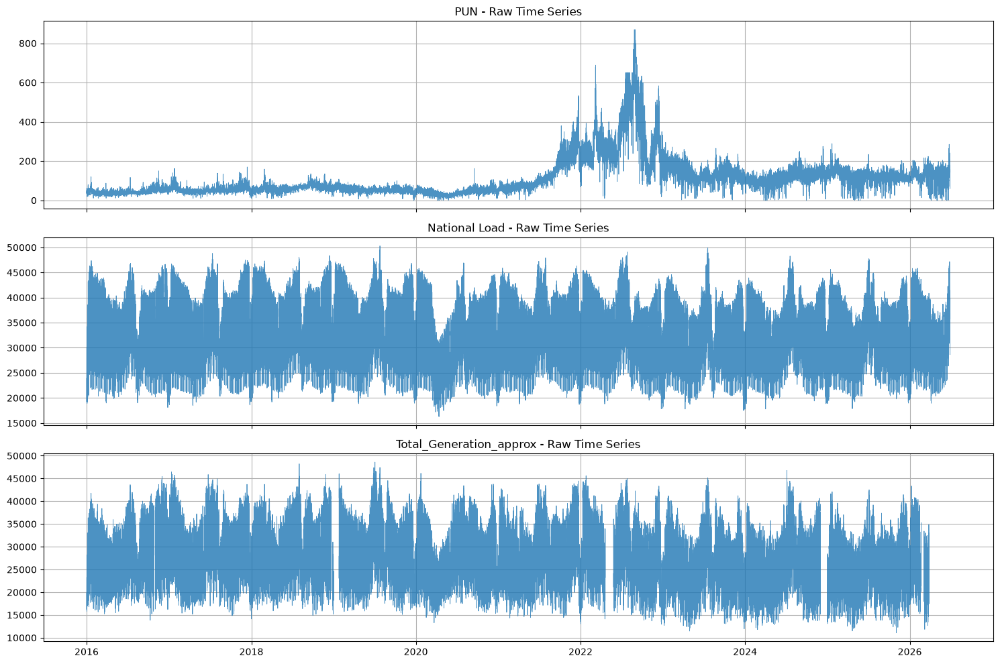

In [26]:
# plot graph
fig, ax = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

for i, col in enumerate(cols):
    ax[i].plot(df['datetime_UTC'], df[col], linewidth=0.6, alpha=0.8)
    ax[i].set_title(f'{col} - Raw Time Series')
    ax[i].grid(True)

plt.tight_layout()
plt.show()

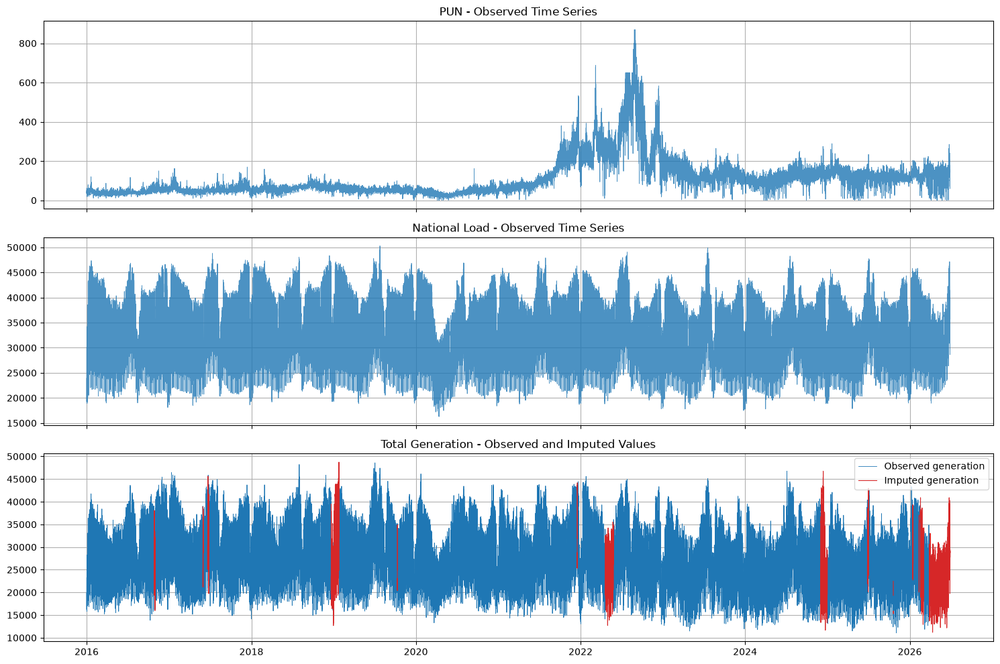

In [27]:
# prices, load and generation (with imputated values) 
fig, ax = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

# PUN
ax[0].plot(
    df["datetime_UTC"],
    df["PUN"],
    linewidth=0.6,
    alpha=0.8
)
ax[0].set_title("PUN - Observed Time Series")
ax[0].grid(True)

# National load
ax[1].plot(
    df["datetime_UTC"],
    df["National Load"],
    linewidth=0.6,
    alpha=0.8
)
ax[1].set_title("National Load - Observed Time Series")
ax[1].grid(True)

# Generation: observed AND imputed values
ax[2].plot(
    df_viz["datetime_UTC"],
    df_viz["Total_Generation_observed_plot"],
    color="tab:blue",
    linewidth=0.6,
    label="Observed generation"
)

ax[2].plot(
    df_viz["datetime_UTC"],
    df_viz["Total_Generation_imputed_plot"],
    color="tab:red",
    linewidth=0.8,
    label="Imputed generation"
)

ax[2].set_title("Total Generation - Observed and Imputed Values")
ax[2].legend()
ax[2].grid(True)

plt.tight_layout()
plt.show()


Note: Observed generation values are shown in blue, while imputed values are shown in orange. Imputation is performed exclusively for visualization purposes; all econometric analyses use the original, non-imputed dataset.

### 2.3.2. Rolling mean

To smooth short-term fluctuations in the hourly observations and highlight broader temporal patterns, a 24-hour rolling mean is calculated.

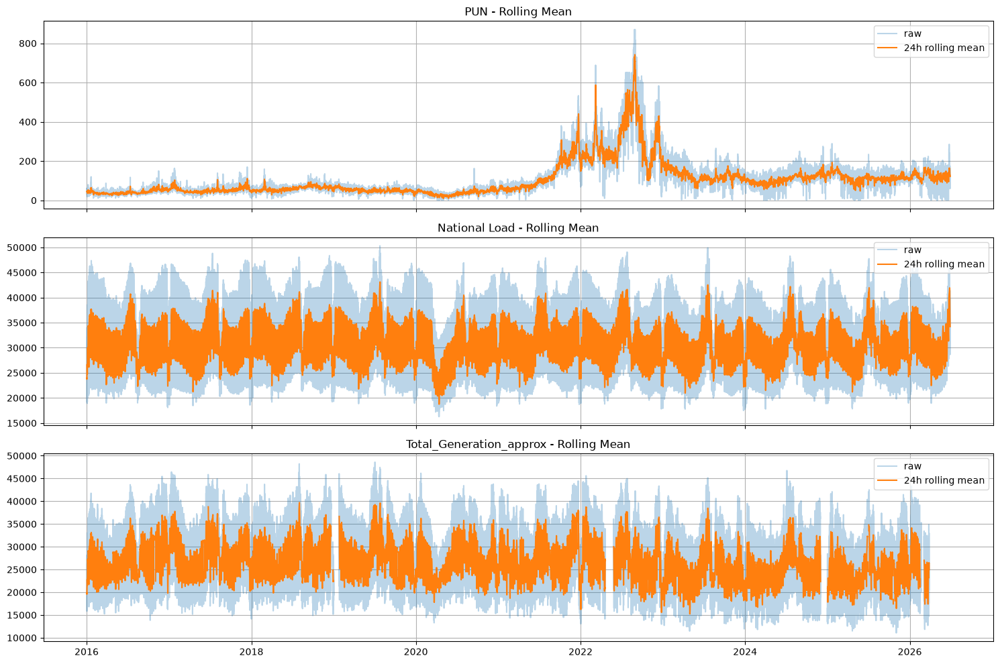

In [28]:
# define rolling window
window = 24  # 24h rolling window (1 day)

fig, ax = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

for i, col in enumerate(cols):
    ax[i].plot(df['datetime_UTC'], df[col], alpha=0.3, label='raw')
    ax[i].plot(df['datetime_UTC'], df[col].rolling(window).mean(), label='24h rolling mean')
    ax[i].set_title(f'{col} - Rolling Mean')
    ax[i].legend()
    ax[i].grid(True)

plt.tight_layout()
plt.show()

### 2.3.3. Volatility of first differences

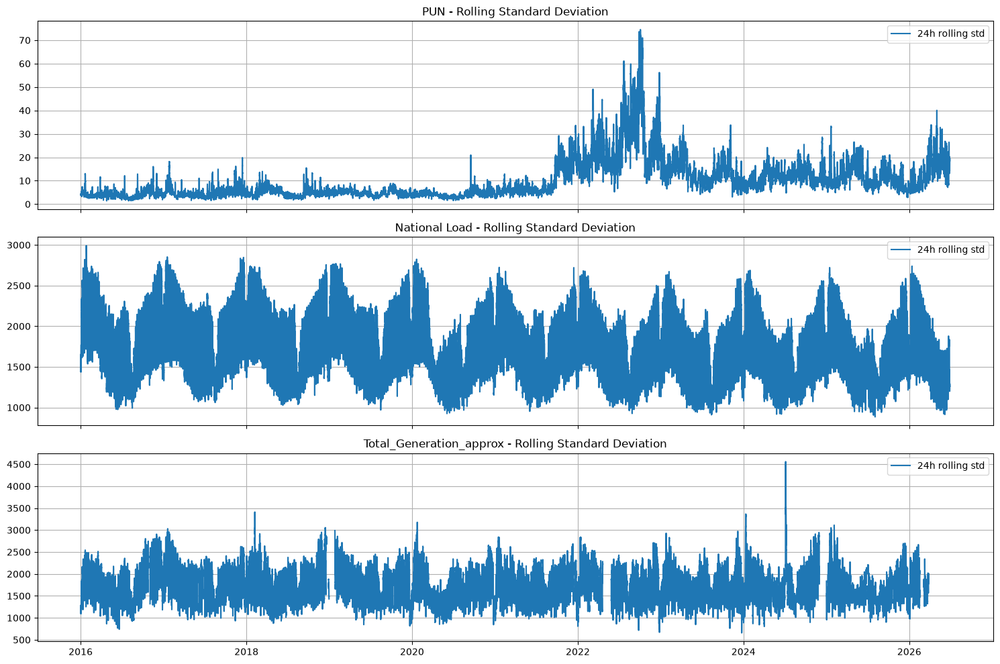

In [29]:
fig, ax = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

for i, col in enumerate(cols):
    ax[i].plot(df['datetime_UTC'], df[col].diff().rolling(window).std(), label='24h rolling std')
    ax[i].set_title(f'{col} - Rolling Standard Deviation')
    ax[i].legend()
    ax[i].grid(True)

plt.tight_layout()
plt.show()

### 2.3.4. Daily prices and major market events

In [30]:
# convert hourly data in daily data
daily_prices = (
    df
    .set_index('datetime_UTC')[f'{price_col_name}']
    .resample('D')
    .mean()
)

In [31]:
# create event DF
events = pd.DataFrame({
    'Date': pd.to_datetime([
        '2020-03-09',
        '2020-06-03',
        '2021-07-01',
        '2021-12-01',
        '2022-02-24',
        '2022-08-01',
        '2022-09-26',
        '2023-05-01',
        '2024-12-12',
        '2025-07-01',
        '2026-02-28'
    ]),
    
    'Event': [
        'COVID-19 Lockdown - Start',
        'COVID-19 Lockdown - End',
        'Tight LNG supply',
        'Low hydro and nuclear availability',
        'Russian invasion of Ukraine',
        'Low wind and nuclear availability',
        'Nord Stream sabotage',
        'Gas TTF normalization phase',
        'Dunkelflaute*',
        'European Heatwave*',
        'Hormuz crisis'
    ],
    
    'Ticker': [
       'E1',
       'E2',
       'E3',
       'E4',
       'E5',
       'E6',
       'E7',
       'E8',
       'E9',
       'E10',
       'E11'
    ],
    
    'Category': [
        'Energy-system shock',
        'Energy-system shock',
        'Energy-system shock',
        'Energy-system shock',
        'Geopolitical - Supply shocks',
        'Energy-system shock',
        'Geopolitical - Supply shocks',
        'Regime transition',
        'Energy-system shock',
        'Energy-system shock',
        'Geopolitical - Supply shocks'
    ]
})

# define label positions
events['level'] = [0.025, 0.025, 0.025, 0.025, 0.025, 0.025, 0.025, 0.025, 0.025, 0.025, 0.025]

events

,Date,Event,Ticker,Category,level
0,2020-03-09,COVID-19 Lockdown - Start,E1,Energy-system shock,0.025
1,2020-06-03,COVID-19 Lockdown - End,E2,Energy-system shock,0.025
2,2021-07-01,Tight LNG supply,E3,Energy-system shock,0.025
3,2021-12-01,Low hydro and nuclear availability,E4,Energy-system shock,0.025
4,2022-02-24,Russian invasion of Ukraine,E5,Geopolitical - Supply shocks,0.025
5,2022-08-01,Low wind and nuclear availability,E6,Energy-system shock,0.025
6,2022-09-26,Nord Stream sabotage,E7,Geopolitical - Supply shocks,0.025
7,2023-05-01,Gas TTF normalization phase,E8,Regime transition,0.025
8,2024-12-12,Dunkelflaute*,E9,Energy-system shock,0.025
9,2025-07-01,European Heatwave*,E10,Energy-system shock,0.025


[Bundesnetzagentur](https://www.bundesnetzagentur.de/SharedDocs/Pressemitteilungen/EN/2025/20251021_Preisspitzen.html?nn=691794) writes about Dunkelflaute between November 5th–7th and December 11th–12th 2024.

About the European heatwave, [Copernicus](https://climate.copernicus.eu/heatwaves-contribute-warmest-june-record-western-europe) documents episodes between June and July 2025 
The line in the graph on July 1st is used as a refernce, and does display a phase, not a single date.

About Hormuz cris, the beginning of the attacks is collocated on February 28th ([Reuters, 2026](https://www.reuters.com/world/middle-east/iran-says-it-will-reply-us-response-hormuz-proposal-once-review-over-2026-10-12/))

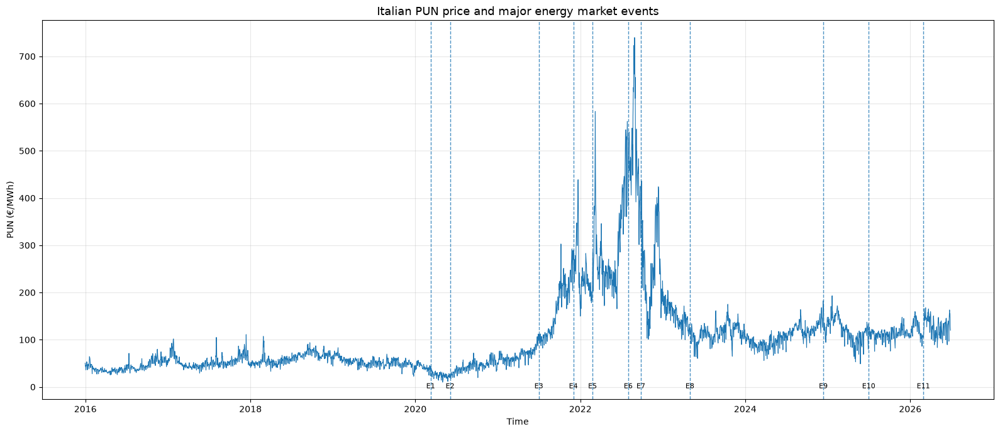

In [32]:
# display daily prices with significant events
fig, ax = plt.subplots(figsize=(16, 7))

# PUN time series
ax.plot(
    daily_prices.index,
    daily_prices.values,
    linewidth=0.8
)

# important events
for _, event in events.iterrows():
    # vertical line
    ax.axvline(
        event['Date'],
        linestyle='--',
        linewidth=1,
        alpha=0.8
    )

    # event label
    ax.text(
        event['Date'],
        event['level'],
        event['Ticker'],
        transform=ax.get_xaxis_transform(),
        rotation=0,
        ha='center',
        va='bottom',
        fontsize=8
    )

# labels and title
ax.set_title(
    'Italian PUN price and major energy market events',
    fontsize=13
)

ax.set_xlabel('Time')
ax.set_ylabel('PUN (€/MWh)')

ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 2.3.5. Evolution of the Italian generation mix
Monthly average generation by selected core technologies.  
Missing observations are retained as gaps, not replaced with zero.

In [33]:
# technologies included in the core mix
core_plot_cols = list(dict.fromkeys(res_core + fossil))

# work on copy and keep local timestamps for calendar-month aggregation
plot_df = df.copy()
plot_df['datetime_local'] = pd.to_datetime(
    plot_df['datetime_local']
)

plot_df = (
    plot_df
    .sort_values('datetime_UTC')
    .set_index('datetime_local')
)

# monthly average generation (MW)
monthly_mean = (
    plot_df[core_plot_cols]
    .resample('MS')
    .mean()
)

# keep a monthly value only if at least 95% of expected hourly observations are available for that source
monthly_observed = (
    plot_df[core_plot_cols]
    .notna()
    .resample('MS')
    .sum()
)

monthly_expected = plot_df.resample('MS').size()

monthly_coverage = monthly_observed.div(
    monthly_expected, axis=0
)

monthly_mean = monthly_mean.where(
    monthly_coverage >= 0.95
)

# convert to long format for Plotly
plot_long = (
    monthly_mean
    .rename_axis('Month')
    .reset_index()
    .melt(
        id_vars='Month',
        var_name='Technology',
        value_name='Monthly average generation (MW)'
    )
)

# interactive stacked area chart
fig = px.area(
    plot_long,
    x='Month',
    y='Monthly average generation (MW)',
    color='Technology',
    title=(
        'Italian Electricity Generation Mix '
        '(2016–June 2026)'
    ),
    labels={
        'Month': 'Month',
        'Monthly average generation (MW)': 'Average output (MW)',
        'Technology': 'Technology'
    }
)

# preserve gaps where monthly data coverage is insufficient
fig.update_traces(connectgaps=False)

fig.update_layout(
    hovermode='x unified',
    legend_title_text='Technology',
    legend=dict(
        itemclick='toggle',
        itemdoubleclick='toggleothers'
    ),
    xaxis=dict(
        rangeslider=dict(visible=True)
    )
)

fig.show()

## 2.4. Relationship analysis

### 2.4.1. Pearson correlation matrix

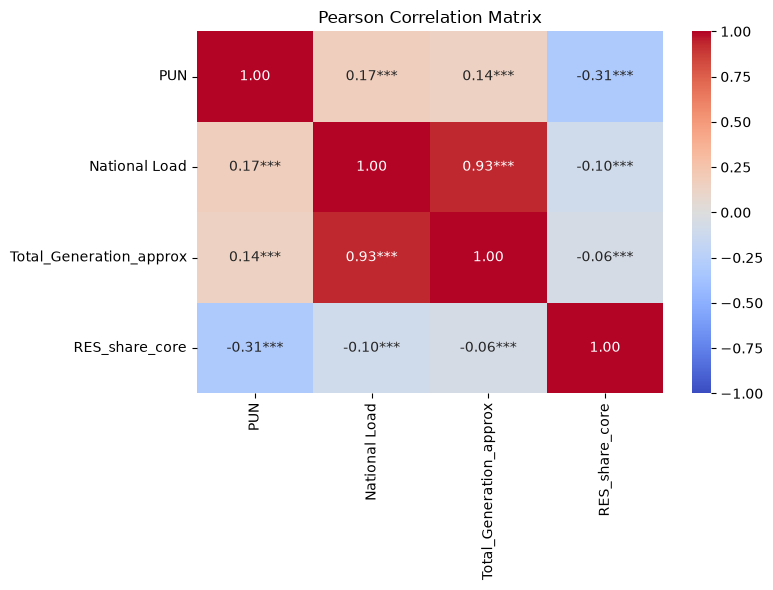

Correlation matrix:


,PUN,National Load,Total_Generation_approx,RES_share_core
PUN,1.0000,0.1671,0.1366,-0.3088
National Load,0.1671,1.0000,0.9323,-0.1008
Total_Generation_approx,0.1366,0.9323,1.0000,-0.0596
RES_share_core,-0.3088,-0.1008,-0.0596,1.0000


P-value matrix:


,PUN,National Load,Total_Generation_approx,RES_share_core
PUN,NaN,0.000000e+00,0.000000e+00,0.000000e+00
National Load,0.0,NaN,0.000000e+00,8.096755e-200
Total_Generation_approx,0.0,0.000000e+00,NaN,6.861452e-69
RES_share_core,0.0,8.096755e-200,6.861452e-69,NaN


Number of observations used for each pair:


,PUN,National Load,Total_Generation_approx,RES_share_core
PUN,91967,91967,86609,89058
National Load,91967,91967,86609,89058
Total_Generation_approx,86609,86609,86609,86609
RES_share_core,89058,89058,86609,89058


In [34]:
# main variables
corr_cols_main = [
    price_col_name,
    load_col_name,
    'Total_Generation_approx',
    'RES_share_core'
]

# initialize matrices
main_corr_matrix = pd.DataFrame(
    np.nan, index=corr_cols_main, columns=corr_cols_main
)
p_matrix = pd.DataFrame(
    np.nan, index=corr_cols_main, columns=corr_cols_main
)
n_matrix = pd.DataFrame(
    0, index=corr_cols_main, columns=corr_cols_main
)

# calculate correlation and p-value using the same pairwise sample
for i, col1 in enumerate(corr_cols_main):
    for j, col2 in enumerate(corr_cols_main):
        pair = (
            df[[col1, col2]]
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )

        n = len(pair)
        n_matrix.loc[col1, col2] = n

        # diagonal: correlation with itself
        if col1 == col2:
            main_corr_matrix.loc[col1, col2] = 1.0
            continue

        if n >= 3 and pair[col1].nunique() > 1 and pair[col2].nunique() > 1:
            r, p = pearsonr(pair[col1], pair[col2])
            main_corr_matrix.loc[col1, col2] = r
            p_matrix.loc[col1, col2] = p

# create annotations
annotations = pd.DataFrame(
    '', index=corr_cols_main, columns=corr_cols_main
)

for row in corr_cols_main:
    for col in corr_cols_main:
        r = main_corr_matrix.loc[row, col]
        p = p_matrix.loc[row, col]

        if pd.isna(r):
            annotations.loc[row, col] = 'NA'
            continue

        if row == col:
            annotations.loc[row, col] = '1.00'
            continue

        if pd.isna(p):
            stars = ''
        elif p < 0.001:
            stars = '***'
        elif p < 0.01:
            stars = '**'
        elif p < 0.05:
            stars = '*'
        else:
            stars = ''

        annotations.loc[row, col] = f'{r:.2f}{stars}'

# plot heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    main_corr_matrix,
    annot=annotations,
    fmt='',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Pearson Correlation Matrix')
plt.tight_layout()
plt.show()

# inspect results
print('Correlation matrix:')
display(main_corr_matrix.round(4))
print('P-value matrix:')
display(p_matrix)
print('Number of observations used for each pair:')
display(n_matrix)

*p-value < 0.05  
**p-value < 0.01  
***p-value < 0.001  

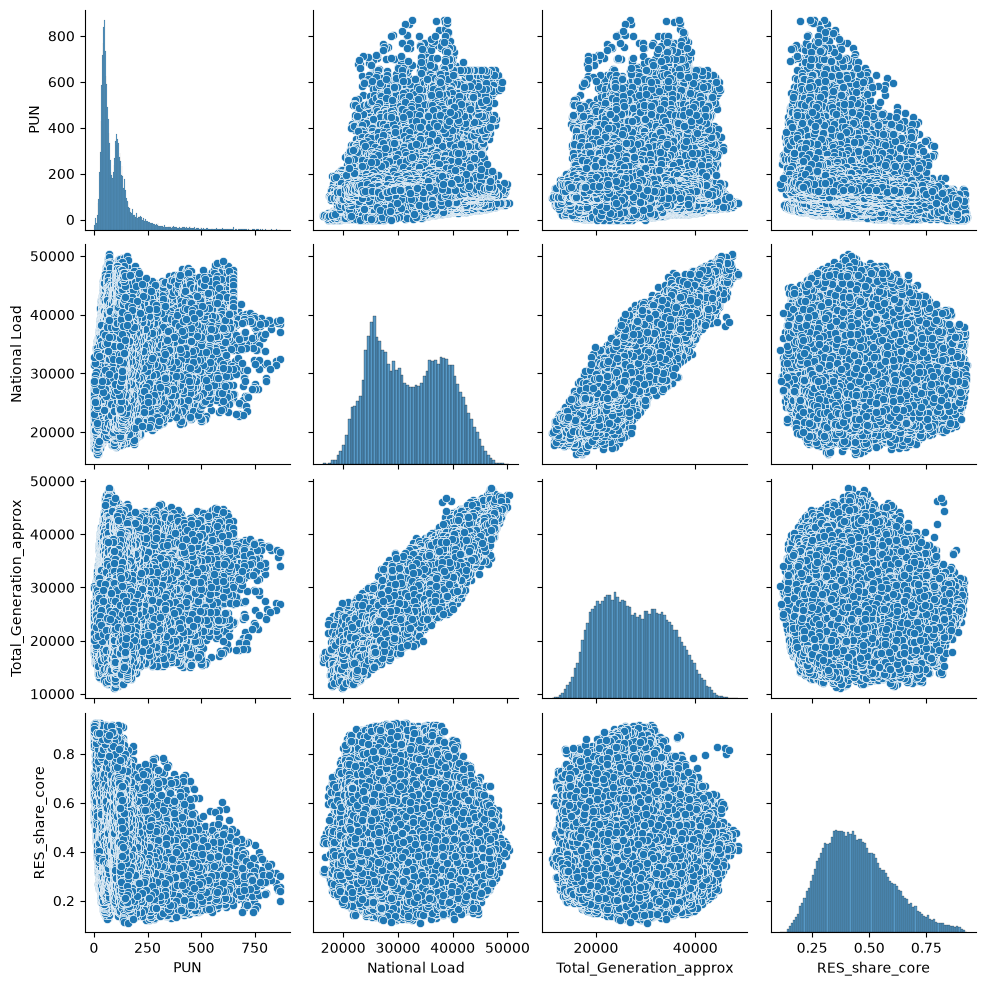

In [ ]:
sns.pairplot(df[corr_cols_main])

In [35]:
# detailed variables
corr_cols_detailed = generation_approx_cols.copy()
corr_cols_detailed.append(f'{price_col_name}')
corr_cols_detailed.append(f'{load_col_name}')
corr_cols_detailed

['Biomass',
 'Fossil Coal-derived gas',
 'Fossil Gas',
 'Fossil Hard coal',
 'Fossil Oil',
 'Geothermal',
 'Hydro Run-of-river and poundage',
 'Hydro Water Reservoir',
 'Other',
 'Solar',
 'Waste',
 'Wind Onshore',
 'Wind Offshore',
 'PUN',
 'National Load']

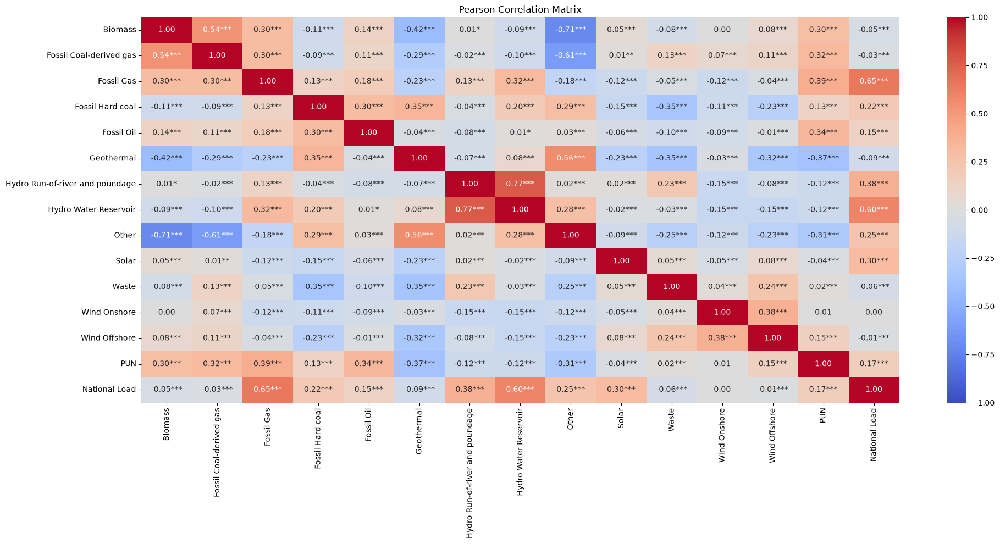

Correlation matrix:


,Biomass,Fossil Coal-derived gas,Fossil Gas,Fossil Hard coal,Fossil Oil,Geothermal,Hydro Run-of-river and poundage,Hydro Water Reservoir,Other,Solar,Waste,Wind Onshore,Wind Offshore,PUN,National Load
Biomass,1.0000,0.5357,0.3022,-0.1056,0.1441,-0.4178,0.0076,-0.0935,-0.7081,0.0508,-0.0751,0.0004,0.0798,0.2962,-0.0488
Fossil Coal-derived gas,0.5357,1.0000,0.3029,-0.0945,0.1050,-0.2885,-0.0222,-0.1025,-0.6129,0.0087,0.1300,0.0709,0.1138,0.3202,-0.0277
Fossil Gas,0.3022,0.3029,1.0000,0.1265,0.1806,-0.2274,0.1302,0.3189,-0.1820,-0.1213,-0.0453,-0.1180,-0.0431,0.3935,0.6498
Fossil Hard coal,-0.1056,-0.0945,0.1265,1.0000,0.3042,0.3513,-0.0392,0.2030,0.2941,-0.1511,-0.3488,-0.1134,-0.2348,0.1265,0.2166
Fossil Oil,0.1441,0.1050,0.1806,0.3042,1.0000,-0.0383,-0.0771,0.0085,0.0289,-0.0602,-0.1036,-0.0852,-0.0118,0.3361,0.1481
Geothermal,-0.4178,-0.2885,-0.2274,0.3513,-0.0383,1.0000,-0.0718,0.0828,0.5623,-0.2298,-0.3541,-0.0328,-0.3250,-0.3702,-0.0933
Hydro Run-of-river and poundage,0.0076,-0.0222,0.1302,-0.0392,-0.0771,-0.0718,1.0000,0.7726,0.0234,0.0173,0.2252,-0.1453,-0.0801,-0.1247,0.3797
Hydro Water Reservoir,-0.0935,-0.1025,0.3189,0.2030,0.0085,0.0828,0.7726,1.0000,0.2836,-0.0244,-0.0262,-0.1534,-0.1509,-0.1236,0.6012
Other,-0.7081,-0.6129,-0.1820,0.2941,0.0289,0.5623,0.0234,0.2836,1.0000,-0.0914,-0.2473,-0.1220,-0.2318,-0.3111,0.2514
Solar,0.0508,0.0087,-0.1213,-0.1511,-0.0602,-0.2298,0.0173,-0.0244,-0.0914,1.0000,0.0488,-0.0482,0.0840,-0.0359,0.3048


P-value matrix:


,Biomass,Fossil Coal-derived gas,Fossil Gas,Fossil Hard coal,Fossil Oil,Geothermal,Hydro Run-of-river and poundage,Hydro Water Reservoir,Other,Solar,Waste,Wind Onshore,Wind Offshore,PUN,National Load
Biomass,NaN,0.000000e+00,0.000000e+00,5.296539e-225,0.000000e+00,0.000000e+00,2.056450e-02,1.880959e-177,0.000000e+00,1.330224e-53,2.421692e-112,9.100151e-01,1.369077e-128,0.000000e+00,1.044379e-49
Fossil Coal-derived gas,0.000000e+00,NaN,0.000000e+00,3.743006e-179,1.707835e-220,0.000000e+00,2.135890e-11,8.712326e-212,0.000000e+00,8.737975e-03,0.000000e+00,3.582873e-102,1.322242e-258,0.000000e+00,6.159943e-17
Fossil Gas,0.000000e+00,0.000000e+00,NaN,2.865581e-322,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.038502e-297,6.366622e-42,4.223551e-282,1.235744e-38,0.000000e+00,0.000000e+00
Fossil Hard coal,5.296539e-225,3.743006e-179,2.865581e-322,NaN,0.000000e+00,0.000000e+00,1.631924e-32,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,3.227379e-259,0.000000e+00,4.940656e-323,0.000000e+00
Fossil Oil,0.000000e+00,1.707835e-220,0.000000e+00,0.000000e+00,NaN,5.885101e-31,3.510524e-120,1.035613e-02,2.840864e-18,5.134809e-74,1.246993e-210,1.849656e-146,3.831526e-04,0.000000e+00,0.000000e+00
Geothermal,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,5.885101e-31,NaN,2.490753e-105,1.889331e-139,0.000000e+00,0.000000e+00,0.000000e+00,2.786086e-23,0.000000e+00,0.000000e+00,8.039256e-177
Hydro Run-of-river and poundage,2.056450e-02,2.135890e-11,0.000000e+00,1.631924e-32,3.510524e-120,2.490753e-105,NaN,0.000000e+00,1.452300e-12,1.551702e-07,0.000000e+00,0.000000e+00,1.124316e-129,1.915446e-315,0.000000e+00
Hydro Water Reservoir,1.880959e-177,8.712326e-212,0.000000e+00,0.000000e+00,1.035613e-02,1.889331e-139,0.000000e+00,NaN,0.000000e+00,1.490271e-13,4.065575e-15,0.000000e+00,0.000000e+00,1.109061e-309,0.000000e+00
Other,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.840864e-18,0.000000e+00,1.452300e-12,0.000000e+00,NaN,1.891772e-169,0.000000e+00,7.403406e-301,0.000000e+00,0.000000e+00,0.000000e+00
Solar,1.330224e-53,8.737975e-03,1.038502e-297,0.000000e+00,5.134809e-74,0.000000e+00,1.551702e-07,1.490271e-13,1.891772e-169,NaN,2.028996e-48,1.677292e-48,3.015965e-142,1.391125e-27,0.000000e+00


Number of observations used for each pair:


,Biomass,Fossil Coal-derived gas,Fossil Gas,Fossil Hard coal,Fossil Oil,Geothermal,Hydro Run-of-river and poundage,Hydro Water Reservoir,Other,Solar,Waste,Wind Onshore,Wind Offshore,PUN,National Load
Biomass,91967,91369,91822,91467,91221,91919,91967,91943,91679,91967,89664,91959,91103,91967,91967
Fossil Coal-derived gas,91369,91369,91224,90893,90623,91321,91369,91345,91201,91369,89088,91361,90505,91369,91369
Fossil Gas,91822,91224,91822,91322,91076,91774,91822,91798,91534,91822,89519,91814,90958,91822,91822
Fossil Hard coal,91467,90893,91322,91467,90721,91419,91467,91443,91179,91467,89164,91459,90603,91467,91467
Fossil Oil,91221,90623,91076,90721,91221,91173,91221,91197,90933,91221,88918,91213,90357,91221,91221
Geothermal,91919,91321,91774,91419,91173,91919,91919,91895,91631,91919,89616,91911,91055,91919,91919
Hydro Run-of-river and poundage,91967,91369,91822,91467,91221,91919,91967,91943,91679,91967,89664,91959,91103,91967,91967
Hydro Water Reservoir,91943,91345,91798,91443,91197,91895,91943,91943,91655,91943,89640,91935,91079,91943,91943
Other,91679,91201,91534,91179,90933,91631,91679,91655,91679,91679,89376,91671,90815,91679,91679
Solar,91967,91369,91822,91467,91221,91919,91967,91943,91679,91967,89664,91959,91103,91967,91967


In [36]:
# initialize matrices
detailed_corr_matrix = pd.DataFrame(
    np.nan,
    index=corr_cols_detailed,
    columns=corr_cols_detailed
)

p_matrix = pd.DataFrame(
    np.nan,
    index=corr_cols_detailed,
    columns=corr_cols_detailed
)

n_matrix = pd.DataFrame(
    0,
    index=corr_cols_detailed,
    columns=corr_cols_detailed
)

for col1 in corr_cols_detailed:
    for col2 in corr_cols_detailed:
        pair = (
            df[[col1, col2]]
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )

        n = len(pair)
        n_matrix.loc[col1, col2] = n

        if col1 == col2:
            detailed_corr_matrix.loc[col1, col2] = 1.0
            continue

        if (
            n >= 3
            and pair[col1].nunique() > 1
            and pair[col2].nunique() > 1
        ):
            r, p = pearsonr(pair[col1], pair[col2])

            detailed_corr_matrix.loc[col1, col2] = r
            p_matrix.loc[col1, col2] = p

# create annotations
annotations = pd.DataFrame(
    '',
    index=corr_cols_detailed,
    columns=corr_cols_detailed
)

for row in corr_cols_detailed:
    for col in corr_cols_detailed:

        r = detailed_corr_matrix.loc[row, col]
        p = p_matrix.loc[row, col]

        if pd.isna(r):
            annotations.loc[row, col] = 'NA'
            continue

        if row == col:
            annotations.loc[row, col] = '1.00'
            continue

        if pd.isna(p):
            stars = ''
        elif p < 0.001:
            stars = '***'
        elif p < 0.01:
            stars = '**'
        elif p < 0.05:
            stars = '*'
        else:
            stars = ''

        annotations.loc[row, col] = f'{r:.2f}{stars}'

# plot heatmap
plt.figure(figsize=(20, 10))
sns.heatmap(
    detailed_corr_matrix,
    annot=annotations,
    fmt='',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0
)
plt.title('Pearson Correlation Matrix')
plt.tight_layout()
plt.show()

# inspect results
print('Correlation matrix:')
display(detailed_corr_matrix.round(4))
print('P-value matrix:')
display(p_matrix)
print('Number of observations used for each pair:')
display(n_matrix)

In [83]:
corr_cols_detailed =[
    'Biomass',
    'Fossil Coal-derived gas',
    'Fossil Gas',
    'Fossil Hard coal',
    'Fossil Oil',
    'Geothermal',
    'Hydro_ror',
    'Hydro_wr',
    'Other',
    'Solar',
    'Waste',
    'Wind Onshore',
    'Wind Offshore',
    'PUN',
    'National Load'
]

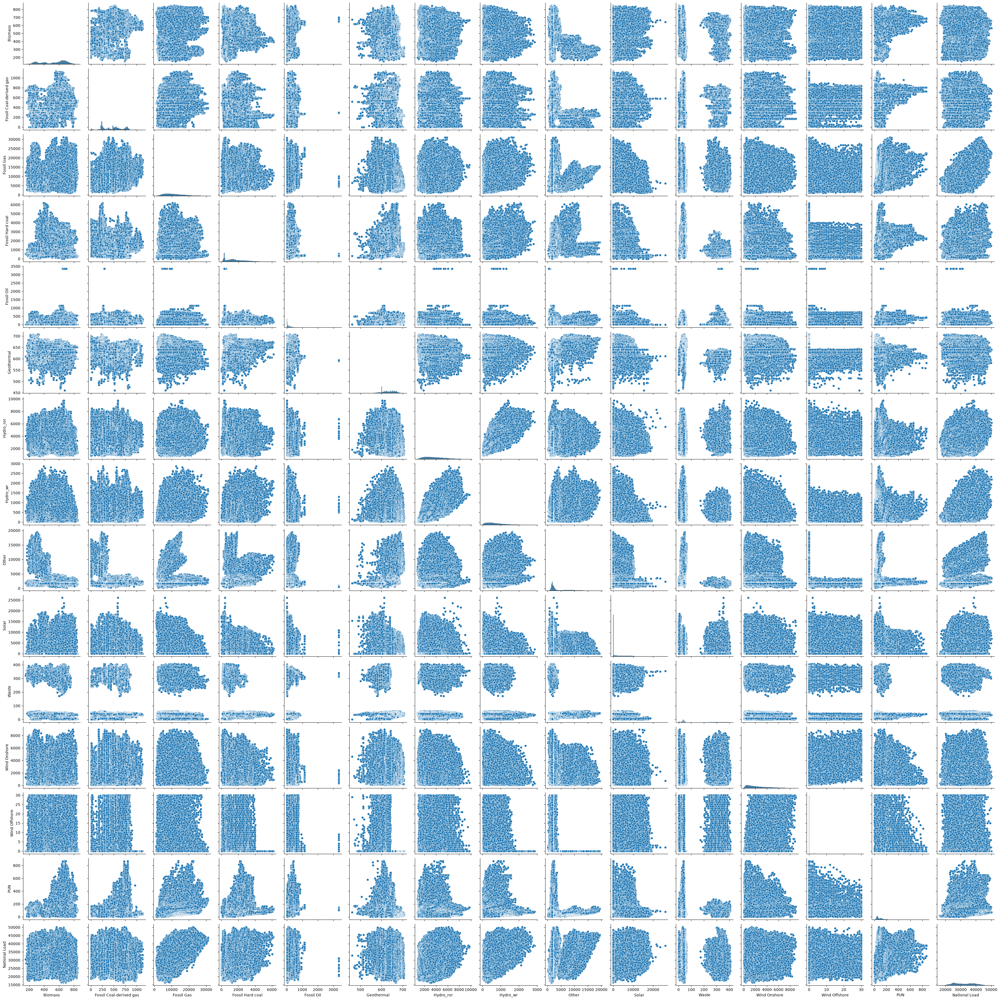

In [84]:
sns.pairplot(df[corr_cols_detailed])

# 3. Econometric Analysis

## 3.1. Econometric framework and model specification

### Research objective
The econometric analysis investigates the relationship between Italian wholesale electricity prices and the conditions of the national electricity system over the period January 2016–June 2026.  
The main objective is to examine whether the association between renewable generation and electricity prices varies across market regimes, and whether demand conditions and generation composition provide additional explanatory information.  
The analysis is exploratory and observational. Estimated coefficients are interpreted as conditional associations and do not, by themselves, identify causal effects or the technology setting the marginal price.

### Dependent variable
The dependent variable is the Italian national wholesale electricity price (`PUN`), expressed in €/MWh.

### Explanatory variables
The analysis considers the following groups of explanatory variables:
- Renewable penetration (`RES_share_core`): the share of selected renewable technologies in the defined core generation mix.
- Market regimes (`Period`): predefined categories used to compare different market conditions.
- National load (`National Load`): electricity demand at national level.
- Residual demand (`Residual_Demand_core`): national load minus the selected renewable generation aggregate.
- Generation technology groups: selected renewable technologies and observed fossil generation, including gas-fired generation.
- Calendar controls: local hour, day of the week and calendar month.
- Gas price: a potential extension, conditional on the availability of a suitable historical price series.

### Model strategy
The analysis proceeds in stages:
1. Static nonrobust models
    1. Baseline model with market-regime and calendar controls.
    2. Renewable penetration model.
    3. Regime-dependent renewable relationship, including interactions.
    4. Load and combined renewable-load specifications.
    5. Residual-demand specification as an alternative representation of system conditions.
    6. Generation-mix specifications to compare technology groups.
2. Selected static HAC covariance
    0. Baseline model
    1. Renewable penetation and market period
    2. Hydropower and price formation
    3. Geographical heterogeneity 
3. Dynamic models incorporating lagged electricity prices and, where justified, lagged explanatory variables.

### Estimation and inference
The static models are estimated using Ordinary Least Squares (OLS). Heteroscedasticity and residual autocorrelation are examined through diagnostic tests and residual analysis.  
Heteroscedasticity and autocorrelation consistent (HAC) standard errors are used where appropriate for statistical inference. HAC standard errors do not remove residual autocorrelation or replace the specification of a dynamic model.  
Model comparisons account for the estimation sample and the number of parameters. Differences in explanatory power are interpreted alongside coefficient estimates, uncertainty and residual diagnostics.

### Limitations
Generation data contain some missing observations and certain technology categories have classification or coverage limitations.  
Aggregate generation measures and residual demand are therefore interpreted according to their explicit definitions.  
The analysis does not directly identify hourly marginal-price-setting technologies. This would require additional market or dispatch data.

## 3.2. Static non-robust regression models

In [37]:
calendar_terms = (
    'C(local_hour) + '
    'C(day_of_week) + '
    'C(local_month)'
)

# model specifications
formulas = {
    'M1_Baseline': (
        f'{price_col_name} ~ C(Period) + {calendar_terms}'
    ),
    'M2_Renewables': (
        f'{price_col_name} ~ RES_share_core + C(Period) + {calendar_terms}'
    ),
    'M2b_Renewables_Regime_Interaction': (
        f'{price_col_name} ~ RES_share_core * C(Period) '
        f'+ {calendar_terms}'
    ),
    'M3_Load': (
        f'{price_col_name} ~ Q("National Load") + C(Period) '
        f'+ {calendar_terms}'
    ),
    'M4_Residual_Demand': (
        f'{price_col_name} ~ Residual_Demand_core + C(Period) '
        f'+ {calendar_terms}'
    ),
    'M5_Generation_Technology': (
        f'{price_col_name} ~ RES_modular'
        ' + RES_variable'
        ' + Fossil'
        ' + C(Period)'
        f' + {calendar_terms}'
    )
}

In [38]:
# prepare dict for storing estimated model results
fitted_models = {}
hac_fitted_models = {}

### 3.2.1. Baseline model

In [39]:
# fit model
model_1 = smf.ols(formulas['M1_Baseline'], data=df).fit()
model_1_hac = smf.ols(
    formulas['M1_Baseline'], 
    data=df
).fit(
    cov_type='HAC',
    cov_kwds={'maxlags':24}
)

# store results
fitted_models['M1_Baseline'] = model_1
hac_fitted_models['M1_Baseline'] = model_1_hac

print(f'\nModel 1: BASELINE\n')
print(model_1.summary())
print(model_1_hac.summary())


Model 1: BASELINE

                            OLS Regression Results                            
Dep. Variable:                    PUN   R-squared:                       0.637
Model:                            OLS   Adj. R-squared:                  0.636
Method:                 Least Squares   F-statistic:                     3745.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:06:20   Log-Likelihood:            -4.9797e+05
No. Observations:               91967   AIC:                         9.960e+05
Df Residuals:                   91923   BIC:                         9.964e+05
Df Model:                          43                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------


### 3.2.2. Renewable penetration

In [40]:
# fit model
model_2 = smf.ols(formulas['M2_Renewables'], data=df).fit()

# store results
fitted_models['M2_Renewables'] = model_2

print(f'\nModel 2: RENEWABLES\n')
print(model_2.summary())


Model 2: RENEWABLES

                            OLS Regression Results                            
Dep. Variable:                    PUN   R-squared:                       0.655
Model:                            OLS   Adj. R-squared:                  0.655
Method:                 Least Squares   F-statistic:                     3848.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:06:24   Log-Likelihood:            -4.8004e+05
No. Observations:               89058   AIC:                         9.602e+05
Df Residuals:                   89013   BIC:                         9.606e+05
Df Model:                          44                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------

### 3.2.3. Renewables and Market-regime interaction

In [41]:
# fit model
model_2b = smf.ols(formulas['M2b_Renewables_Regime_Interaction'], data=df).fit()

# store results
fitted_models['M2b_Renewables_Regime_Interaction'] = model_2b

print(f'\nModel 2b: RENEWABLES AND MARKET REGIMES INTERACTION\n')
print(model_2b.summary())


Model 2b: RENEWABLES AND MARKET REGIMES INTERACTION

                            OLS Regression Results                            
Dep. Variable:                    PUN   R-squared:                       0.670
Model:                            OLS   Adj. R-squared:                  0.669
Method:                 Least Squares   F-statistic:                     3838.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:06:28   Log-Likelihood:            -4.7817e+05
No. Observations:               89058   AIC:                         9.564e+05
Df Residuals:                   89010   BIC:                         9.569e+05
Df Model:                          47                                         
Covariance Type:            nonrobust                                         
                                                coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------

### 3.2.4. Load

In [42]:
# fit model
model_3 = smf.ols(formulas['M3_Load'], data=df).fit()

# store results
fitted_models['M3_Load'] = model_3

print(f'\nModel 3: LOAD\n')
print(model_3.summary())


Model 3: LOAD

                            OLS Regression Results                            
Dep. Variable:                    PUN   R-squared:                       0.653
Model:                            OLS   Adj. R-squared:                  0.652
Method:                 Least Squares   F-statistic:                     3925.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:06:31   Log-Likelihood:            -4.9590e+05
No. Observations:               91967   AIC:                         9.919e+05
Df Residuals:                   91922   BIC:                         9.923e+05
Df Model:                          44                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Inte

### 3.2.5. Residual Demand

In [43]:
# fit model
model_4 = smf.ols(formulas['M4_Residual_Demand'], data=df).fit()

# store results
fitted_models['M4_Residual_Demand'] = model_4

print(f'\nModel 4: RESIDUAL DEMAND*')
print(f'* Residual_demand_core is a proxy for the load that has not been satisfied by the renewable core technologies\n')
print(model_4.summary())


Model 4: RESIDUAL DEMAND*
* Residual_demand_core is a proxy for the load that has not been satisfied by the renewable core technologies

                            OLS Regression Results                            
Dep. Variable:                    PUN   R-squared:                       0.660
Model:                            OLS   Adj. R-squared:                  0.660
Method:                 Least Squares   F-statistic:                     4014.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:06:35   Log-Likelihood:            -4.8923e+05
No. Observations:               91023   AIC:                         9.786e+05
Df Residuals:                   90978   BIC:                         9.790e+05
Df Model:                          44                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|  

### 3.2.6. Static models comparison

In [44]:
comparison_rows = []

for model_name, results in fitted_models.items():
    comparison_rows.append({
        'Model': model_name,
        'Formula': results.model.formula,
        'Observations': int(results.nobs),
        'R_squared': results.rsquared,
        'Adjusted_R_squared': results.rsquared_adj,
        'AIC': results.aic,
        'BIC': results.bic,
        'Covariance_type': results.cov_type
    })

model_comparison = (
    pd.DataFrame(comparison_rows)
    .set_index('Model')
)

model_comparison.round(4)

,Formula,Observations,R_squared,Adjusted_R_squared,AIC,BIC,Covariance_type
Model,,,,,,,
M1_Baseline,PUN ~ C(Period) + C(local_hour) + C(day_of_wee...,91967,0.6366,0.6364,996031.6595,996446.5436,nonrobust
M2_Renewables,PUN ~ RES_share_core + C(Period) + C(local_hou...,89058,0.6554,0.6553,960167.5493,960590.4162,nonrobust
M2b_Renewables_Regime_Interaction,PUN ~ RES_share_core * C(Period) + C(local_hou...,89058,0.6696,0.6694,956438.6758,956889.7338,nonrobust
M3_Load,"PUN ~ Q(""National Load"") + C(Period) + C(local...",91967,0.6526,0.6525,991882.5721,992306.8854,nonrobust
M4_Residual_Demand,PUN ~ Residual_Demand_core + C(Period) + C(loc...,91023,0.6600,0.6599,978550.1789,978974.0280,nonrobust


In [45]:
# coefficient comparison
coefficient_rows = []

for model_name, results in fitted_models.items():
    confidence_intervals = results.conf_int()

    for term in results.params.index:
        coefficient_rows.append({
            'Model': model_name,
            'Term': term,
            'Coefficient': results.params[term],
            'Std_Error': results.bse[term],
            'Test_Statistic': results.tvalues[term],
            'P_value': results.pvalues[term],
            'CI_95_Lower': confidence_intervals.loc[term, 0],
            'CI_95_Upper': confidence_intervals.loc[term, 1]
        })

coefficient_comparison = pd.DataFrame(coefficient_rows)
#coefficient_comparison[coefficient_comparison['Term'] == 'RES_share_core'].round(4)

coefficient_comparison.round(4)

,Model,Term,Coefficient,Std_Error,Test_Statistic,P_value,CI_95_Lower,CI_95_Upper
0,M1_Baseline,Intercept,46.4510,1.1549,40.2200,0.0000,44.1873,48.7146
1,M1_Baseline,C(Period)[T.Demand_crisis],-1.6212,0.5850,-2.7712,0.0056,-2.7678,-0.4746
2,M1_Baseline,C(Period)[T.Supply_crisis],190.5637,0.5158,369.4357,0.0000,189.5527,191.5748
3,M1_Baseline,C(Period)[T.Post_crises],62.9291,0.4336,145.1160,0.0000,62.0792,63.7790
4,M1_Baseline,C(local_hour)[T.1],-5.4888,1.2423,-4.4182,0.0000,-7.9237,-3.0539
...,...,...,...,...,...,...,...,...
222,M4_Residual_Demand,C(local_month)[T.9],19.3348,0.8484,22.7905,0.0000,17.6720,20.9976
223,M4_Residual_Demand,C(local_month)[T.10],8.6216,0.8433,10.2239,0.0000,6.9688,10.2744
224,M4_Residual_Demand,C(local_month)[T.11],9.1206,0.8475,10.7617,0.0000,7.4595,10.7818
225,M4_Residual_Demand,C(local_month)[T.12],20.5467,0.8407,24.4392,0.0000,18.8989,22.1945


In [46]:
# Re-estimate the baseline with HAC standard errors
model_1_hac = smf.ols(
    formula=formulas['M1_Baseline'],
    data=df
).fit(
    cov_type='HAC',
    cov_kwds={'maxlags': 24}
)

# Joint significance tests for model terms
calendar_tests = model_1_hac.wald_test_terms()

calendar_tests.table

,statistic,pvalue,df_constraint
Intercept,382.426166,3.687662e-85,1
C(Period),10046.588138,0.000000e+00,3
C(local_hour),5385.122113,0.000000e+00,23
C(day_of_week),106.546132,1.076682e-20,6
C(local_month),227.548961,1.377468e-42,11


## 3.3. Hypotheses tests


The empirical analysis addresses three main hypotheses. 
1.	**H1 - Temporal stability**: The negative association between renewable generation and Italia wholesale electricity prices varies over time and across market conditions
2.	**H2 - Hydropower and price formation**: Hydropower generation from water reservoir plants exhibits a different price relationship from other renewable technologies, reflecting the role of water storage, the opportunity cost of water and strategic generation decisions.
3.	**H3 – Geographical heterogeneity**: The association between wind and solar generation and wholesale electricity prices is more negative in southern bidding zones, where these tech-nologies have a greater presence, than in other areas of Italy.

In [47]:
df = df.copy()
df = df.rename(columns={
    'Hydro Run-of-river and poundage': 'Hydro_ror',
    'Hydro Water Reservoir': 'Hydro_wr'
})
df.columns.tolist()

['datetime_UTC',
 'datetime_local',
 'local_hour',
 'PUN',
 'National Load',
 'Biomass',
 'Fossil Coal-derived gas',
 'Fossil Gas',
 'Fossil Hard coal',
 'Fossil Oil',
 'Geothermal',
 'Hydro Pumped Storage',
 'Hydro_ror',
 'Hydro_wr',
 'Other',
 'Solar',
 'Waste',
 'Wind Onshore',
 'Wind Offshore',
 'Energy storage',
 'Other renewable',
 'Geothermal_source',
 'Hydro',
 'Wind',
 'Fossil',
 'RES_core',
 'Total_Generation_approx',
 'Generation_approx_missing_components',
 'Generation_approx_completeness_pct',
 'Total_Generation_core',
 'Core_Generation_Missing_Components',
 'Core_Generation_Completeness_pct',
 'RES_share_core',
 'Residual_Demand_core',
 'day_of_week',
 'local_month',
 'Period']

In [48]:
ds_path = Path('../dataset/filled')
df_zonal_long = pd.read_csv(
    ds_path / 'long-zonal.csv',
    low_memory=False
)
df_zonal_long = df_zonal_long[:-1]
df_zonal_long.head()

,datetime_UTC,datetime_local,local_hour,prices,load,Biomass,Fossil Gas,Fossil Oil,Hydro Pumped Storage,Hydro Run-of-river and poundage,...,Waste,Wind Onshore,Fossil Hard coal,Fossil Coal-derived gas,Geothermal,Energy storage,Other renewable,zone,Wind Offshore,Geothermal_source
0,2015-12-31 23:00:00+00:00,2016-01-01 00:00:00+01:00,0,50.41211,23927.233,220.0,5588.0,542.0,0.0,1259.0,...,45.0,203.0,1686.0,241.0,706.0,NaN,NaN,IT,0.0,ENTSO-E
1,2016-01-01 00:00:00+00:00,2016-01-01 01:00:00+01:00,1,44.76435,22517.279,216.0,5034.0,519.0,0.0,1163.0,...,46.0,218.0,1719.0,241.0,706.0,NaN,NaN,IT,0.0,ENTSO-E
2,2016-01-01 01:00:00+00:00,2016-01-01 02:00:00+01:00,2,40.01613,21354.678,217.0,4486.0,530.0,0.0,1089.0,...,44.0,267.0,1728.0,241.0,706.0,NaN,NaN,IT,0.0,ENTSO-E
3,2016-01-01 02:00:00+00:00,2016-01-01 03:00:00+01:00,3,37.92076,20219.874,216.0,4275.0,467.0,0.0,1010.0,...,39.0,227.0,1727.0,241.0,705.0,NaN,NaN,IT,0.0,ENTSO-E
4,2016-01-01 03:00:00+00:00,2016-01-01 04:00:00+01:00,4,35.77287,19229.221,215.0,3926.0,426.0,0.0,988.0,...,44.0,212.0,1658.0,241.0,707.0,NaN,NaN,IT,0.0,ENTSO-E


In [ ]:
import numpy as np

# date parsing
df_zonal_long['datetime_UTC'] = pd.to_datetime(df_zonal_long['datetime_UTC'], utc=True)
df_zonal_long['datetime_local'] = pd.to_datetime(df_zonal_long['datetime_local'], utc=True)
df_zonal_long['datetime_local'] = df_zonal_long['datetime_local'].dt.tz_convert(f'{timezone}')

# calendar variables reconstruction
df_zonal_long['local_hour'] = (
    df_zonal_long['datetime_local'].dt.hour
)

df_zonal_long['day_of_week'] = (
    df_zonal_long['datetime_local'].dt.dayofweek
)

df_zonal_long['local_month'] = (
    df_zonal_long['datetime_local'].dt.month
)

# define market periods
date = df_zonal_long['datetime_local']

conditions = [
    (date >= '2016-01-01') & (date < '2020-03-09'),
    (date >= '2020-03-09') & (date < '2021-07-01'),
    (date >= '2021-07-01') & (date < '2023-05-01'),
    (date >= '2023-05-01') & (date < '2026-07-01')
]

periods = [
    'Pre_crises',
    'Demand_crisis',
    'Supply_crisis',
    'Post_crises'
]

df_zonal_long['Period'] = pd.Series(
    np.select(conditions, periods, default=None),
    index=df_zonal_long.index,
    dtype='object'
)

# set market period order
df_zonal_long['Period'] = pd.Categorical(
    df_zonal_long['Period'],
    categories=periods,
    ordered=True
)

# checks
print("Intervallo temporale:")
print(df_zonal_long['datetime_local'].min())
print(df_zonal_long['datetime_local'].max())
print("\nValori mancanti nelle variabili di calendario:")
print(
    df_zonal_long[
        ['local_hour', 'day_of_week', 'local_month', 'Period']
    ].isna().sum()
)
print("\nOsservazioni per regime:")
print(df_zonal_long['Period'].value_counts(sort=False))
print("\nOsservazioni per zona e regime:")
display(
    df_zonal_long.groupby(
        ['zone', 'Period'],
        observed=False
    ).size().unstack(fill_value=0)
)

Intervallo temporale:
2015-01-01 00:00:00+01:00
2026-06-30 23:00:00+02:00

Valori mancanti nelle variabili di calendario:
local_hour         0
day_of_week        0
local_month        0
Period         61320
dtype: int64

Osservazioni per regime:
Period
Pre_crises       293568
Demand_crisis     91960
Supply_crisis    128448
Post_crises      222143
Name: count, dtype: int64

Osservazioni per zona e regime:


Period,Pre_crises,Demand_crisis,Supply_crisis,Post_crises
zone,,,,
IT,36696,11495,16056,27768
IT_CALA,36696,11495,16056,27768
IT_CNOR,36696,11495,16056,27768
IT_CSUD,36696,11495,16056,27768
IT_NORD,36696,11495,16056,27768
IT_SARD,36696,11495,16056,27768
IT_SICI,36696,11495,16056,27768
IT_SUD,36696,11495,16056,27767


In [50]:
df_zonal_long['Wind'] = df_zonal_long[wind].sum(axis=1, min_count=len(wind))

In [51]:
df_zonal_long.columns.tolist()

['datetime_UTC',
 'datetime_local',
 'local_hour',
 'prices',
 'load',
 'Biomass',
 'Fossil Gas',
 'Fossil Oil',
 'Hydro Pumped Storage',
 'Hydro Run-of-river and poundage',
 'Hydro Water Reservoir',
 'Other',
 'Solar',
 'Waste',
 'Wind Onshore',
 'Fossil Hard coal',
 'Fossil Coal-derived gas',
 'Geothermal',
 'Energy storage',
 'Other renewable',
 'zone',
 'Wind Offshore',
 'Geothermal_source',
 'day_of_week',
 'local_month',
 'Period',
 'Wind']

In [52]:
calendar_terms = (
    'C(local_hour) + '
    'C(day_of_week) + '
    'C(local_month)'
)

# model specifications
formulas = {
    'M0_Baseline': (
        f'{price_col_name} ~ C(Period) + {calendar_terms}'
    ),
    'M1_Renewables_Regime_Interaction': (
        f'{price_col_name} ~ RES_share_core * C(Period) '
        f'+ {calendar_terms}'
    ),
    'M2_Generation_Technology': (
        f'{price_col_name} ~ Biomass'
        ' + Geothermal'
        ' + Hydro_ror'
        ' + Hydro_wr'
        ' + Wind'
        ' + Solar'
        ' + Fossil'
        ' + C(Period)'
        f' + {calendar_terms}'
    ),
    'M3_Zonal_Generation': (
        'prices ~ C(zone) + '
        'Solar * C(zone) + '
        'Wind * C(zone) + '
        'load + '
        'C(Period)'
        f' + {calendar_terms}'
    )
}

### 3.3.1. Model 0 - Baseline model

In [53]:
# fit model
model_0_hac = smf.ols(
    formulas['M0_Baseline'], 
    data=df
).fit(
    cov_type='HAC',
    cov_kwds={'maxlags':24}
)

# store results
hac_fitted_models['M0_Baseline'] = model_0_hac

print(f'\nModel 0: BASELINE\n')
print(model_0_hac.summary())


Model 0: BASELINE

                            OLS Regression Results                            
Dep. Variable:                    PUN   R-squared:                       0.637
Model:                            OLS   Adj. R-squared:                  0.636
Method:                 Least Squares   F-statistic:                     412.7
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:07:08   Log-Likelihood:            -4.9797e+05
No. Observations:               91967   AIC:                         9.960e+05
Df Residuals:                   91923   BIC:                         9.964e+05
Df Model:                          43                                         
Covariance Type:                  HAC                                         
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------


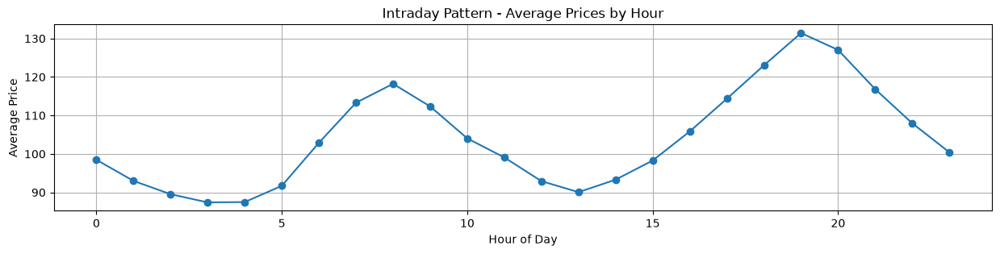

In [54]:
# group hours and calculate average prices
hourly_pattern = df.groupby('local_hour')['PUN'].mean()

# display graph
plt.figure(figsize=(15,3))
plt.plot(hourly_pattern.index, hourly_pattern.values, marker='o')
plt.title('Intraday Pattern - Average Prices by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Price')
plt.grid(True)
plt.show()

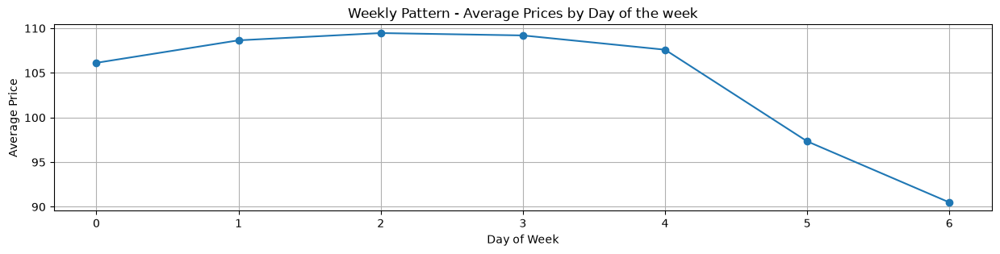

In [55]:
# group hours and calculate average prices
weekly_pattern = df.groupby('day_of_week')['PUN'].mean()

# display graph
plt.figure(figsize=(15,3))
plt.plot(weekly_pattern.index, weekly_pattern.values, marker='o')
plt.title('Weekly Pattern - Average Prices by Day of the week')
plt.xlabel('Day of Week')
plt.ylabel('Average Price')
plt.grid(True)
plt.show()

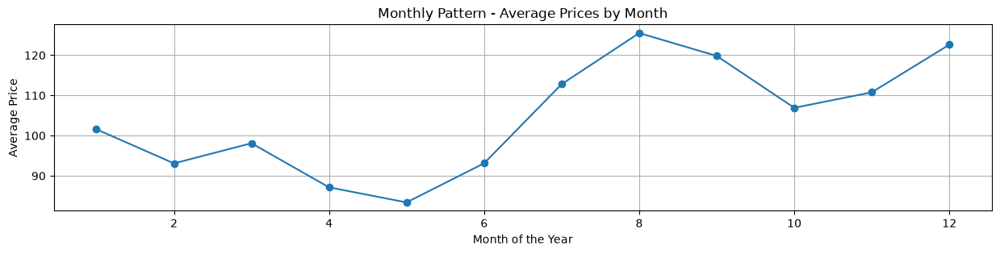

In [56]:
# group hours and calculate average prices
monthly_pattern = df.groupby('local_month')['PUN'].mean()

# display graph
plt.figure(figsize=(15,3))
plt.plot(monthly_pattern.index, monthly_pattern.values, marker='o')
plt.title('Monthly Pattern - Average Prices by Month')
plt.xlabel('Month of the Year')
plt.ylabel('Average Price')
plt.grid(True)
plt.show()

### 3.3.2. Model 1 - Temporal stability

In [57]:
# fit model
model_1_hac = smf.ols(
    formulas['M1_Renewables_Regime_Interaction'], 
    data=df
).fit(
    cov_type='HAC',
    cov_kwds={'maxlags':24}
)

# store results
hac_fitted_models['M1_Renewables_Regime_Interaction'] = model_1_hac

print(f'\nModel 1: RENEWABLES AND REGIME INTERACTION\n')
print(model_1_hac.summary())


Model 1: RENEWABLES AND REGIME INTERACTION

                            OLS Regression Results                            
Dep. Variable:                    PUN   R-squared:                       0.670
Model:                            OLS   Adj. R-squared:                  0.669
Method:                 Least Squares   F-statistic:                     458.0
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:07:15   Log-Likelihood:            -4.7817e+05
No. Observations:               89058   AIC:                         9.564e+05
Df Residuals:                   89010   BIC:                         9.569e+05
Df Model:                          47                                         
Covariance Type:                  HAC                                         
                                                coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------

In [58]:
# model params for visualization
params = model_1_hac.params

# x values
x = np.linspace(
    df['RES_share_core'].min(),
    df['RES_share_core'].max(),
    100
)

# coefficients
b0 = model_1_hac.params['Intercept']
b1 = model_1_hac.params['RES_share_core']
b2 = model_1_hac.params['C(Period)[T.Post_crises]']
b3 = model_1_hac.params['C(Period)[T.Post_crises]']
b4 = model_1_hac.params['RES_share_core:C(Period)[T.Post_crises]']
b5 = model_1_hac.params['RES_share_core:C(Period)[T.Post_crises]']

# f lines
y_shock = b0 + b1 * x
y_post = b0 + b1 * x + b2 + b4 * x
y_pre = b0 + b1 * x + b3 + b5 * x

In [59]:
# extensions of x to see what happens when renewables is 0% and 100%
x_ext = np.linspace(0, 1, 100)

fig = px.scatter(
    df,
    x='RES_share_core',
    y='PUN',
    color='Period',
    trendline='ols', 
    opacity=0.05
)

results = px.get_trendline_results(fig)

for _, row in results.iterrows():
    regime = row['Period']
    regime_robust_model = row['px_fit_results']

    intercept = regime_robust_model.params[0]
    slope = regime_robust_model.params[1]

    y_ext = intercept + slope * x_ext

    fig.add_trace(
        go.Scatter(
            x=x_ext,
            y=y_ext,
            mode='lines',
            name=f'{regime} extension',
            line=dict(
                dash='dash',
                width=2
            ),
            hovertemplate=(
                f'Regime: {regime}<br>'
                'Renewables: %{x:.2f}<br>'
                'Predicted Price: %{y:.2f}'
                '<extra></extra>'
            )
        )
    )

fig.add_vline(
    x=0,
    line_dash='dot',
    line_color='black'
)

### 3.3.3. Model 2 - Hydropower and price formation

In [60]:
# fit model
model_2_hac = smf.ols(
    formulas['M2_Generation_Technology'], 
    data=df
).fit(
    cov_type='HAC',
    cov_kwds={'maxlags':24}
)

# store results
hac_fitted_models['M2_Generation_Technology'] = model_2_hac

print(f'\nModel 2: GENERATION TECHNOLOGY\n')
print(model_2_hac.summary())


Model 2: GENERATION TECHNOLOGY

                            OLS Regression Results                            
Dep. Variable:                    PUN   R-squared:                       0.672
Model:                            OLS   Adj. R-squared:                  0.672
Method:                 Least Squares   F-statistic:                     381.3
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:07:33   Log-Likelihood:            -4.7779e+05
No. Observations:               89058   AIC:                         9.557e+05
Df Residuals:                   89007   BIC:                         9.562e+05
Df Model:                          50                                         
Covariance Type:                  HAC                                         
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------

In [61]:
df

,datetime_UTC,datetime_local,local_hour,PUN,National Load,Biomass,Fossil Coal-derived gas,Fossil Gas,Fossil Hard coal,Fossil Oil,...,Generation_approx_missing_components,Generation_approx_completeness_pct,Total_Generation_core,Core_Generation_Missing_Components,Core_Generation_Completeness_pct,RES_share_core,Residual_Demand_core,day_of_week,local_month,Period
0,2015-12-31 23:00:00+00:00,2016-01-01 00:00:00+01:00,0,50.41211,23927.233,220.00,241.00,5588.00,1686.00,542.00,...,0,100.000000,10732.00,0,100.0,0.249255,21252.233,4,1,Pre_crises
1,2016-01-01 00:00:00+00:00,2016-01-01 01:00:00+01:00,1,44.76435,22517.279,216.00,241.00,5034.00,1719.00,519.00,...,0,100.000000,9898.00,0,100.0,0.240958,20132.279,4,1,Pre_crises
2,2016-01-01 01:00:00+00:00,2016-01-01 02:00:00+01:00,2,40.01613,21354.678,217.00,241.00,4486.00,1728.00,530.00,...,0,100.000000,9284.00,0,100.0,0.247630,19055.678,4,1,Pre_crises
3,2016-01-01 02:00:00+00:00,2016-01-01 03:00:00+01:00,3,37.92076,20219.874,216.00,241.00,4275.00,1727.00,467.00,...,0,100.000000,8888.00,0,100.0,0.245050,18041.874,4,1,Pre_crises
4,2016-01-01 03:00:00+00:00,2016-01-01 04:00:00+01:00,4,35.77287,19229.221,215.00,241.00,3926.00,1658.00,426.00,...,0,100.000000,8393.00,0,100.0,0.255213,17087.221,4,1,Pre_crises
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91962,2026-06-28 17:00:00+00:00,2026-06-28 19:00:00+02:00,19,159.01250,39430.200,669.50,484.00,18400.75,0.00,167.00,...,1,92.307692,27392.00,0,100.0,0.304478,31089.950,6,6,Post_crises
91963,2026-06-28 18:00:00+00:00,2026-06-28 20:00:00+02:00,20,156.20537,39870.800,669.00,484.00,19244.75,39.25,166.75,...,1,92.307692,26913.25,0,100.0,0.259296,32892.300,6,6,Post_crises
91964,2026-06-28 19:00:00+00:00,2026-06-28 21:00:00+02:00,21,158.80250,39625.500,681.00,483.25,20084.50,129.00,167.00,...,1,92.307692,27238.25,0,100.0,0.234028,33251.000,6,6,Post_crises
91965,2026-06-28 20:00:00+00:00,2026-06-28 22:00:00+02:00,22,155.93208,38308.300,684.75,481.25,19984.00,223.25,167.00,...,1,92.307692,26866.00,0,100.0,0.223721,32297.800,6,6,Post_crises


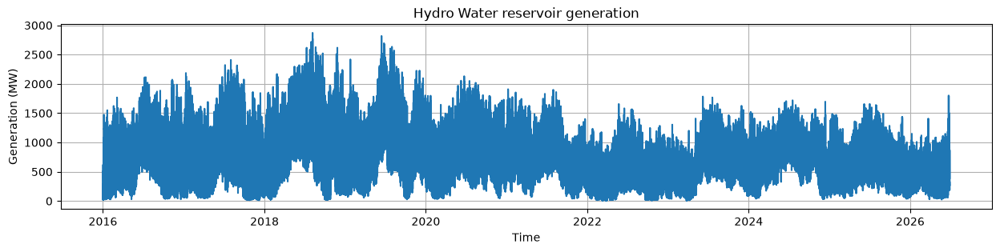

In [62]:
# display graph
plt.figure(figsize=(15,3))
plt.plot(df['datetime_local'], df['Hydro_wr'].values)
plt.title('Hydro Water reservoir generation')
plt.xlabel('Time')
plt.ylabel('Generation (MW)')
plt.grid(True)
plt.show()

### 3.3.4. Model 3 - Geographical heterogeneity

In [63]:
# fit model
model_3_hac = smf.ols(
    formulas['M3_Zonal_Generation'], 
    data=df_zonal_long
).fit(
    cov_type='HAC',
    cov_kwds={'maxlags':24}
)

# store results
hac_fitted_models['M3_Zonal_Generation'] = model_3_hac

print(f'\nModel 3: ZONAL GENERATION MIX\n')
print(model_3_hac.summary())


Model 3: ZONAL GENERATION MIX

                            OLS Regression Results                            
Dep. Variable:                 prices   R-squared:                       0.622
Model:                            OLS   Adj. R-squared:                  0.622
Method:                 Least Squares   F-statistic:                     448.0
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:08:10   Log-Likelihood:            -6.9737e+05
No. Observations:              127046   AIC:                         1.395e+06
Df Residuals:                  126996   BIC:                         1.395e+06
Df Model:                          49                                         
Covariance Type:                  HAC                                         
                                 coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------

## 3.4. Robusteness tests

# Old models (to archive)

In [64]:
data = df.copy()

In [65]:
# model variables
VAR_X = 'RES_share_core'
VAR_Y = 'PUN'

formula = f'{VAR_Y} ~ {VAR_X}'

model = smf.ols(formula, data=data).fit()
print(f'\nLinear Regression Model - Prices and Renewables\n')
print(model.summary())


Linear Regression Model - Prices and Renewables

                            OLS Regression Results                            
Dep. Variable:                    PUN   R-squared:                       0.095
Model:                            OLS   Adj. R-squared:                  0.095
Method:                 Least Squares   F-statistic:                     9386.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:08:10   Log-Likelihood:            -5.2302e+05
No. Observations:               89058   AIC:                         1.046e+06
Df Residuals:                   89056   BIC:                         1.046e+06
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------

In [66]:
# get params for line equation
params = model.params

# x values
ax_x = f'{VAR_X}'
x = np.linspace(0, 1, 100)

# coefficients
b0 = model.params['Intercept']
b1 = model.params[f'{VAR_X}']

# f lines
y_d_0 = b0 + b1 * x 


In [67]:
fig = px.scatter(
    data, 
    x= f'{VAR_X}', 
    y=f'{VAR_Y}', 
    hover_data={
        f'{VAR_X}': True,
        f'{VAR_Y}': True, 
        'datetime_UTC': True
    }, 
    opacity=0.05
)

fig.add_trace(
    go.Scatter(
        x=x,
        y=y_d_0,
        mode='lines',
        name='Power Prices',
        line=dict(width=4)
    )
)

fig.update_layout(
    title='Linear Regression (OLS)',
    xaxis_title='Renewables share',
    yaxis_title='Prices',
    template='simple_white'
)

fig.show()

##### 2.5.1.2. Simple Model evaluation

Before commenting the regression results, it is necessary to execute basic tests on:
1. Heteroscedasticity
2. Autocorrelation of the residuals


##### 1. Heteroscedasticity - Breusch-Pagan test

In [68]:
from statsmodels.stats.diagnostic import het_breuschpagan

# Breusch-Pagan test
bp_test = het_breuschpagan(
    model.resid,
    model.model.exog
)

bp_labels = [
    'LM Statistic',
    'LM p-value',
    'F Statistic',
    'F p-value'
]

print('\nBreusch-Pagan Test')
for label, value in zip(bp_labels, bp_test):
    print(f'{label}: {value:.4f}')


Breusch-Pagan Test
LM Statistic: 2421.5975
LM p-value: 0.0000
F Statistic: 2489.2284
F p-value: 0.0000


p-value < 0.05 indicates that the null hypothesis (homoschedasticity) is refused and therefore, that there is evidence of heteroscedasticity.

##### 2. Residuals Autocorrelation

In [69]:
from statsmodels.stats.diagnostic import acorr_breusch_godfrey

# Breusch-Godfrey test
bg_test = acorr_breusch_godfrey(
    model,
    nlags=24    # 24 hrs lag correlation
)

bg_labels = [
    'LM Statistic',
    'LM p-value',
    'F Statistic',
    'F p-value'
]

print('\nBreusch-Godfrey Test')
for label, value in zip(bg_labels, bg_test):
    print(f'{label}: {value:.4f}')


Breusch-Godfrey Test
LM Statistic: 87809.1773
LM p-value: 0.0000
F Statistic: 260839.8909
F p-value: 0.0000


H0: no autocorrelation until the lag taken into consideration  
vs  
H1: autocorrelation

p-value < 0.05 indicates the residuals autocorrelation.


In [70]:
# Durbin-Watson test check
from statsmodels.stats.stattools import durbin_watson

dw = durbin_watson(model.resid)

print(f'\nDurbin-Watson statistic: {dw:.4f}')


Durbin-Watson statistic: 0.0227


Durbin-Watson value 0.04 < 2 indicates a strong positive autocorrelation of the residuals. This result is consistent with former Breusch-Godfrey test which confirms autocorrelation.

Having these results about the former linear regression model, the same model is displayed with HAC covariance in ordere to have more accurate data on standard errores and significance of the coefficients.

##### 2.5.1.3. Model correction

In [71]:
# hac model
bivariate_hac_model = smf.ols(
    formula, 
    data=data
).fit(
    cov_type='HAC', 
    cov_kwds={
        'maxlags':24
    }
)

print(f'\nLinear Regression Model - Prices and Renewables (2021 - 2026)\n')
print(bivariate_hac_model.summary())


Linear Regression Model - Prices and Renewables (2021 - 2026)

                            OLS Regression Results                            
Dep. Variable:                    PUN   R-squared:                       0.095
Model:                            OLS   Adj. R-squared:                  0.095
Method:                 Least Squares   F-statistic:                     575.0
Date:                Wed, 28 Oct 2026   Prob (F-statistic):          1.14e-126
Time:                        21:08:13   Log-Likelihood:            -5.2302e+05
No. Observations:               89058   AIC:                         1.046e+06
Df Residuals:                   89056   BIC:                         1.046e+06
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------

#### 2.5.2. Regime-dependent relationship

##### 2.5.2.1. Model implementation

In [72]:
# interaction
regime_interaction_model = smf.ols(
    f'{price_col_name} ~ RES_share_core * Period',
    data=data
).fit()

print(regime_interaction_model.summary())

                            OLS Regression Results                            
Dep. Variable:                    PUN   R-squared:                       0.636
Model:                            OLS   Adj. R-squared:                  0.636
Method:                 Least Squares   F-statistic:                 2.224e+04
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:08:14   Log-Likelihood:            -4.8247e+05
No. Observations:               89058   AIC:                         9.650e+05
Df Residuals:                   89050   BIC:                         9.650e+05
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                             coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------

##### 5.2.2. Model evaluation

This model will be evaluated by: 
1. Heteroscedasticity
2. Residuals autocorrelation
3. Multicollinearity

##### 1. Heteroscedasticity

In [73]:
# Breusch-Pagan test
bp_test = het_breuschpagan(
    regime_interaction_model.resid,
    regime_interaction_model.model.exog
)

bp_labels = [
    'LM Statistic',
    'LM p-value',
    'F Statistic',
    'F p-value'
]

print('\nBreusch-Pagan Test')
for label, value in zip(bp_labels, bp_test):
    print(f'{label}: {value:.4f}')


Breusch-Pagan Test
LM Statistic: 15203.1313
LM p-value: 0.0000
F Statistic: 2618.7244
F p-value: 0.0000


#### 2. Residuals autocorrelation

In [74]:
# Breusch-Godfrey test
bg_test = acorr_breusch_godfrey(
    regime_interaction_model,
    nlags=24    # 24 hrs lag correlation
)

bg_labels = [
    'LM Statistic',
    'LM p-value',
    'F Statistic',
    'F p-value'
]

print('\nBreusch-Godfrey Test')
for label, value in zip(bg_labels, bg_test):
    print(f'{label}: {value:.4f}')


Breusch-Godfrey Test
LM Statistic: 86153.4385
LM p-value: 0.0000
F Statistic: 110026.5909
F p-value: 0.0000


In [75]:
# Durbin-Watson test check
dw = durbin_watson(regime_interaction_model.resid)

print(f'\nDurbin-Watson statistic: {dw:.4f}')


Durbin-Watson statistic: 0.0534


#### 3. Multicollinearity

In [76]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = regime_interaction_model.model.exog
feature_names = regime_interaction_model.model.exog_names

vif = pd.DataFrame({
    'Variable': feature_names,
    'VIF': [
        variance_inflation_factor(X, i)
        for i in range(X.shape[1])
    ]
})

print('\nVariance Inflation Factors')
print(vif)


Variance Inflation Factors
                                 Variable        VIF
0                               Intercept   1.000000
1                 Period[T.Demand_crisis]  16.616631
2                 Period[T.Supply_crisis]  12.259042
3                   Period[T.Post_crises]  12.975796
4                          RES_share_core   3.180744
5  RES_share_core:Period[T.Demand_crisis]  16.486156
6  RES_share_core:Period[T.Supply_crisis]  10.932373
7    RES_share_core:Period[T.Post_crises]  15.105389


#### 5.2.3. Model correction

In [77]:
# robust model to heteroskedasticity and autocorrelation
regime_robust_model = smf.ols(
     f'{price_col_name} ~ RES_share_core * Period',
    data=data
).fit(
    cov_type='HAC',
    cov_kwds={'maxlags':24}
)

print(regime_robust_model.summary())

                            OLS Regression Results                            
Dep. Variable:                    PUN   R-squared:                       0.636
Model:                            OLS   Adj. R-squared:                  0.636
Method:                 Least Squares   F-statistic:                     2547.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:08:15   Log-Likelihood:            -4.8247e+05
No. Observations:               89058   AIC:                         9.650e+05
Df Residuals:                   89050   BIC:                         9.650e+05
Df Model:                           7                                         
Covariance Type:                  HAC                                         
                                             coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------

In [78]:
# model params for visualization
params = regime_robust_model.params

# x values
x = np.linspace(
    data['RES_share_core'].min(),
    data['RES_share_core'].max(),
    100
)

# coefficients
b0 = regime_robust_model.params['Intercept']
b1 = regime_robust_model.params['RES_share_core']
b2 = regime_robust_model.params['Period[T.Post_crises]']
b3 = regime_robust_model.params['Period[T.Post_crises]']
b4 = regime_robust_model.params['RES_share_core:Period[T.Post_crises]']
b5 = regime_robust_model.params['RES_share_core:Period[T.Post_crises]']

# f lines
y_shock = b0 + b1 * x
y_post = b0 + b1 * x + b2 + b4 * x
y_pre = b0 + b1 * x + b3 + b5 * x

In [79]:
# extensions of x to see what happens when renewables is 0% and 100%
x_ext = np.linspace(0, 1, 100)

fig = px.scatter(
    data,
    x=f'{VAR_X}',
    y=f'{VAR_Y}',
    color='Period',
    trendline='ols', 
    opacity=0.05
)

results = px.get_trendline_results(fig)

for _, row in results.iterrows():
    regime = row['Period']
    regime_robust_model = row['px_fit_results']

    intercept = regime_robust_model.params[0]
    slope = regime_robust_model.params[1]

    y_ext = intercept + slope * x_ext

    fig.add_trace(
        go.Scatter(
            x=x_ext,
            y=y_ext,
            mode='lines',
            name=f'{regime} extension',
            line=dict(
                dash='dash',
                width=2
            ),
            hovertemplate=(
                f'Regime: {regime}<br>'
                'Renewables: %{x:.2f}<br>'
                'Predicted Price: %{y:.2f}'
                '<extra></extra>'
            )
        )
    )

fig.add_vline(
    x=0,
    line_dash='dot',
    line_color='black'
)